<a href="https://colab.research.google.com/github/Pratyaydevil/Box-Office/blob/main/EDA_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")


#1Loading the dataset

url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv"

df = pd.read_csv(url)

print("\nFIRST FIVE RECORDS")
print(df.head())

print("\nLAST FIVE RECORDS")
print(df.tail())

print("\nDATASET DIMENSIONS")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATASET INFORMATION")
df.info()



FIRST FIVE RECORDS
   rownames  inlf  hours  kidslt6  kidsge6  age  educ    wage  repwage  hushrs  husage  huseduc  huswage  faminc     mtr  motheduc  fatheduc  unem  \
0         1     1   1610        1        0   32    12  3.3540     2.65    2708      34       12   4.0288   16310  0.7215        12         7   5.0   
1         2     1   1656        0        2   30    12  1.3889     2.65    2310      30        9   8.4416   21800  0.6615         7         7  11.0   
2         3     1   1980        1        3   35    12  4.5455     4.04    3072      40       12   3.5807   21040  0.6915        12         7   5.0   
3         4     1    456        0        3   34    12  1.0965     3.25    1920      53       10   3.5417    7300  0.7815         7         7   5.0   
4         5     1   1568        1        2   31    14  4.5918     3.60    2000      32       12  10.0000   27300  0.6215        12        14   9.5   

   city  exper   nwifeinc     lwage  expersq  
0     0     14  10.910060  1.210

In [ ]:
# 2. BASIC STATISTICAL ANALYSIS


print("\nSUMMARY STATISTICS")
print(df.describe().T)

print("\nMEAN OF NUMERICAL COLUMNS")
print(df.mean(numeric_only=True))

print("\nMEDIAN OF NUMERICAL COLUMNS")
print(df.median(numeric_only=True))

print("\nSTANDARD DEVIATION")
print(df.std(numeric_only=True))

print("\nMINIMUM VALUES")
print(df.min(numeric_only=True))

print("\nMAXIMUM VALUES")
print(df.max(numeric_only=True))

print("\nVARIANCE")
print(df.var(numeric_only=True))

print("\nSKEWNESS")
print(df.skew(numeric_only=True))

print("\nNUMBER OF UNIQUE VALUES")
print(df.nunique())

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNUMERICAL COLUMNS")
print(numerical_columns)

print("\nCATEGORICAL COLUMNS")
print(categorical_columns)



SUMMARY STATISTICS
          count          mean           std          min           25%           50%           75%           max
rownames  753.0    377.000000    217.516666     1.000000    189.000000    377.000000    565.000000    753.000000
inlf      753.0      0.568393      0.495630     0.000000      0.000000      1.000000      1.000000      1.000000
hours     753.0    740.576361    871.314216     0.000000      0.000000    288.000000   1516.000000   4950.000000
kidslt6   753.0      0.237716      0.523959     0.000000      0.000000      0.000000      0.000000      3.000000
kidsge6   753.0      1.353254      1.319874     0.000000      0.000000      1.000000      2.000000      8.000000
age       753.0     42.537849      8.072574    30.000000     36.000000     43.000000     49.000000     60.000000
educ      753.0     12.286853      2.280246     5.000000     12.000000     12.000000     13.000000     17.000000
wage      428.0      4.177682      3.310282     0.128200      2.262600      

In [ ]:
# 3. HANDLING MISSING DATA

print("\nMISSING VALUES IN EACH COLUMN")
missing_values = df.isnull().sum()
print(missing_values)

print("\nMISSING VALUE PERCENTAGE")
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

print("\nMISSING DATA SUMMARY")
print(missing_summary)

print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\nROWS CONTAINING MISSING VALUES")
print(df[df.isnull().any(axis=1)].head(20))



df_clean = df.copy()

# Replace missing numerical values with median
numeric_columns_with_missing = df_clean.select_dtypes(
    include=np.number
).columns[df_clean.select_dtypes(include=np.number).isnull().any()]

for column in numeric_columns_with_missing:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)

# Replace missing categorical values with mode
categorical_columns_with_missing = df_clean.select_dtypes(
    exclude=np.number
).columns[df_clean.select_dtypes(exclude=np.number).isnull().any()]

for column in categorical_columns_with_missing:
    mode_value = df_clean[column].mode()[0]
    df_clean[column] = df_clean[column].fillna(mode_value)

print("\nMISSING VALUES AFTER IMPUTATION")
print(df_clean.isnull().sum())

print("\nTOTAL MISSING VALUES AFTER IMPUTATION")
print(df_clean.isnull().sum().sum())




MISSING VALUES IN EACH COLUMN
rownames      0
inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64

MISSING VALUE PERCENTAGE
rownames     0.00
inlf         0.00
hours        0.00
kidslt6      0.00
kidsge6      0.00
age          0.00
educ         0.00
wage        43.16
repwage      0.00
hushrs       0.00
husage       0.00
huseduc      0.00
huswage      0.00
faminc       0.00
mtr          0.00
motheduc     0.00
fatheduc     0.00
unem         0.00
city         0.00
exper        0.00
nwifeinc     0.00
lwage       43.16
expersq      0.00
dtype: float64

MISSING DATA SUMMARY
          Missing Values  Missing Percentage
rownames               0                0.00
inlf                 

In [ ]:
# 4. DATA CLEANING


print("\nNUMBER OF DUPLICATE RECORDS")
print(df_clean.duplicated().sum())


df_clean = df_clean.drop_duplicates()

print("\nDATASET SIZE AFTER REMOVING DUPLICATES")
print(df_clean.shape)


if "rownames" in df_clean.columns:
    df_clean = df_clean.drop(columns=["rownames"])

# Remove unnecessary spaces and convert column names to lowercase
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("\nCLEANED COLUMN NAMES")
print(df_clean.columns.tolist())

print("\nDATA TYPES")
print(df_clean.dtypes)

print("\nUNIQUE VALUES OF BINARY COLUMNS")

binary_columns = ["inlf", "city"]

for column in binary_columns:
    if column in df_clean.columns:
        print(f"\n{column}")
        print(df_clean[column].value_counts())


# Add meaningful labels
if "inlf" in df_clean.columns:
    df_clean["labour_force_status"] = df_clean["inlf"].map({
        1: "In Labour Force",
        0: "Not in Labour Force"
    })

if "city" in df_clean.columns:
    df_clean["city_status"] = df_clean["city"].map({
        1: "City",
        0: "Non-City"
    })


NUMBER OF DUPLICATE RECORDS
0

DATASET SIZE AFTER REMOVING DUPLICATES
(753, 23)

CLEANED COLUMN NAMES
['inlf', 'hours', 'kidslt6', 'kidsge6', 'age', 'educ', 'wage', 'repwage', 'hushrs', 'husage', 'huseduc', 'huswage', 'faminc', 'mtr', 'motheduc', 'fatheduc', 'unem', 'city', 'exper', 'nwifeinc', 'lwage', 'expersq']

DATA TYPES
inlf          int64
hours         int64
kidslt6       int64
kidsge6       int64
age           int64
educ          int64
wage        float64
repwage     float64
hushrs        int64
husage        int64
huseduc       int64
huswage     float64
faminc        int64
mtr         float64
motheduc      int64
fatheduc      int64
unem        float64
city          int64
exper         int64
nwifeinc    float64
lwage       float64
expersq       int64
dtype: object

UNIQUE VALUES OF BINARY COLUMNS

inlf
inlf
1    428
0    325
Name: count, dtype: int64

city
city
1    484
0    269
Name: count, dtype: int64


In [ ]:
# 5. OUTLIER DETECTION AND HANDLING

outlier_columns = [
    "hours",
    "wage",
    "faminc",
    "exper",
    "nwifeinc"
]

print("\nOUTLIER SUMMARY USING IQR METHOD")

for column in outlier_columns:
    if column in df_clean.columns:
        q1 = df_clean[column].quantile(0.25)
        q3 = df_clean[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = df_clean[
            (df_clean[column] < lower_bound) |
            (df_clean[column] > upper_bound)
        ]

        print(
            f"{column}: {len(outliers)} outliers, "
            f"lower bound = {lower_bound:.2f}, "
            f"upper bound = {upper_bound:.2f}"
        )


# Cap outliers instead of deleting records
df_transformed = df_clean.copy()

for column in outlier_columns:
    if column in df_transformed.columns:
        q1 = df_transformed[column].quantile(0.25)
        q3 = df_transformed[column].quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        df_transformed[column] = df_transformed[column].clip(
            lower=lower_bound,
            upper=upper_bound
        )



OUTLIER SUMMARY USING IQR METHOD
hours: 2 outliers, lower bound = -2274.00, upper bound = 3790.00
wage: 226 outliers, lower bound = 2.23, upper bound = 4.72
faminc: 31 outliers, lower bound = -3730.00, upper bound = 47358.00
exper: 16 outliers, lower bound = -12.50, upper bound = 31.50
nwifeinc: 35 outliers, lower bound = -4.14, upper bound = 41.63


In [ ]:
# 5 DATA TRANSFORMATION


# Create total number of children
df_transformed["total_children"] = (
    df_transformed["kidslt6"] +
    df_transformed["kidsge6"]
)

# Create age groups
df_transformed["age_group"] = pd.cut(
    df_transformed["age"],
    bins=[20, 30, 40, 50, 60, 70],
    labels=["21-30", "31-40", "41-50", "51-60", "61-70"],
    include_lowest=True
)

# Create education groups
df_transformed["education_level"] = pd.cut(
    df_transformed["educ"],
    bins=[0, 10, 12, 16, 20],
    labels=[
        "Basic Education",
        "High School",
        "College",
        "Higher Education"
    ],
    include_lowest=True
)

# Log transformation
df_transformed["log_faminc"] = np.log1p(
    df_transformed["faminc"]
)

df_transformed["log_hours"] = np.log1p(
    df_transformed["hours"]
)

# Min-Max normalization
minmax_scaler = MinMaxScaler()

normalization_columns = [
    "age",
    "educ",
    "exper",
    "faminc",
    "hours"
]

normalized_columns = [
    column for column in normalization_columns
    if column in df_transformed.columns
]

normalized_data = minmax_scaler.fit_transform(
    df_transformed[normalized_columns]
)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=[
        f"{column}_normalized"
        for column in normalized_columns
    ],
    index=df_transformed.index
)

df_transformed = pd.concat(
    [df_transformed, normalized_df],
    axis=1
)

# Standardization
standard_scaler = StandardScaler()

standardized_data = standard_scaler.fit_transform(
    df_transformed[normalized_columns]
)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=[
        f"{column}_standardized"
        for column in normalized_columns
    ],
    index=df_transformed.index
)

df_transformed = pd.concat(
    [df_transformed, standardized_df],
    axis=1
)

print("\nTRANSFORMED DATASET")
print(df_transformed.head())

print("\nFINAL DATASET DIMENSIONS")
print(df_transformed.shape)



TRANSFORMED DATASET
   inlf  hours  kidslt6  kidsge6  age  educ     wage  repwage  hushrs  husage  huseduc  huswage  faminc     mtr  motheduc  fatheduc  unem  city  \
0     1   1610        1        0   32    12  3.35400     2.65    2708      34       12   4.0288   16310  0.7215        12         7   5.0     0   
1     1   1656        0        2   30    12  2.23465     2.65    2310      30        9   8.4416   21800  0.6615         7         7  11.0     1   
2     1   1980        1        3   35    12  4.54550     4.04    3072      40       12   3.5807   21040  0.6915        12         7   5.0     0   
3     1    456        0        3   34    12  2.23465     3.25    1920      53       10   3.5417    7300  0.7815         7         7   5.0     0   
4     1   1568        1        2   31    14  4.59180     3.60    2000      32       12  10.0000   27300  0.6215        12        14   9.5     1   

   exper   nwifeinc     lwage  expersq labour_force_status city_status  total_children age_group

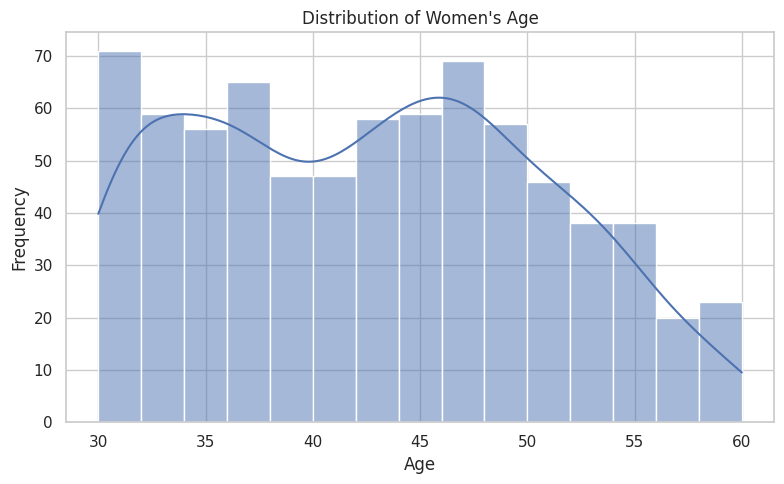

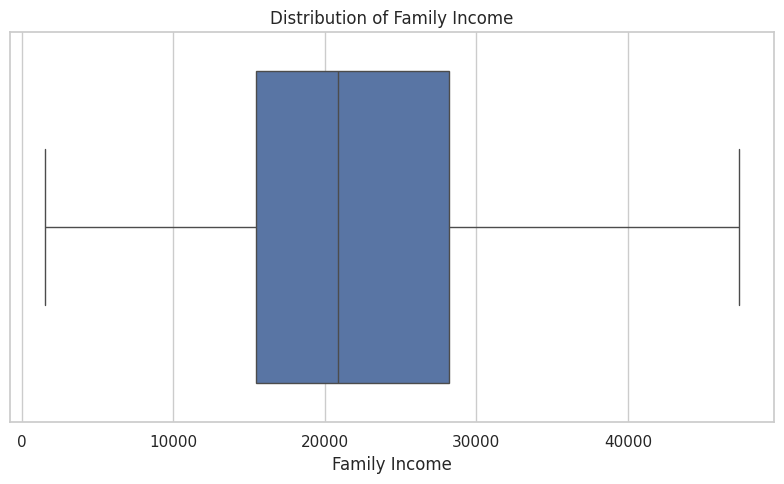

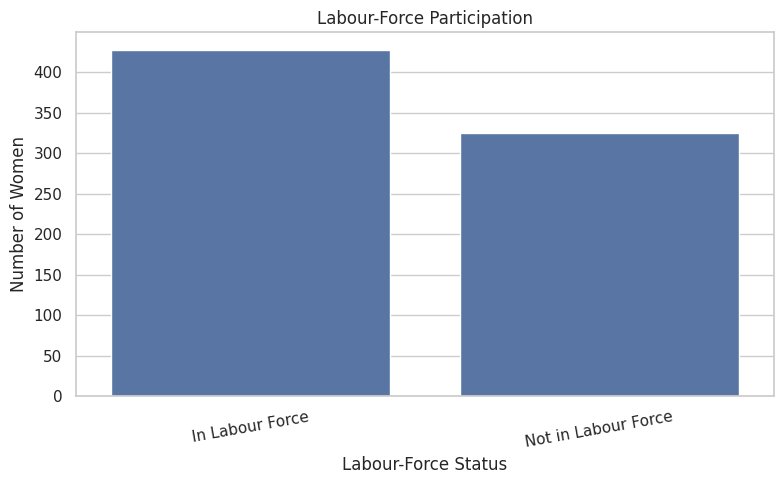

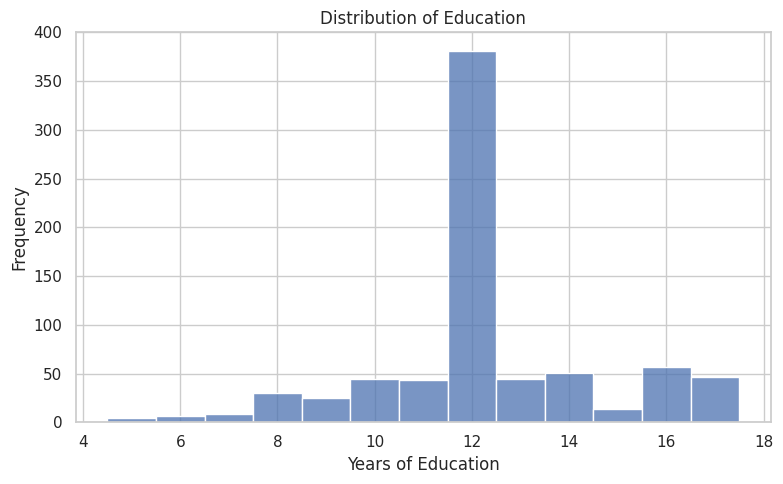

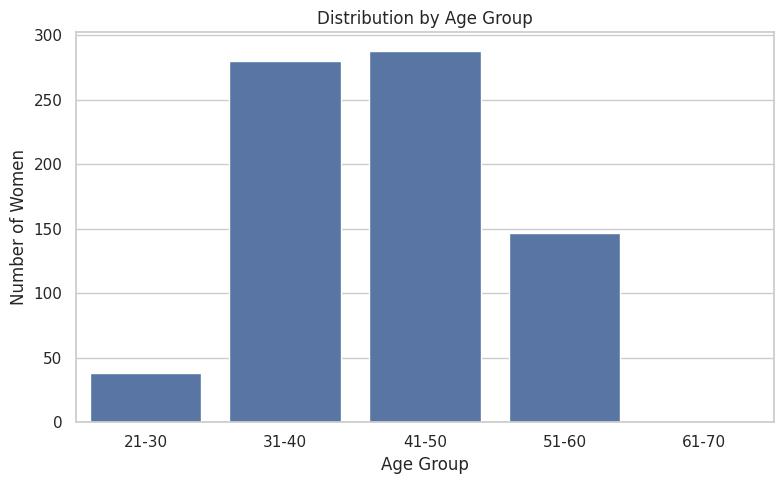

In [ ]:
# 6. UNIVARIATE ANALYSIS
# Minimum three visualizations



# Visualization 1: Histogram of age
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_transformed,
    x="age",
    bins=15,
    kde=True
)

plt.title("Distribution of Women's Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Visualization 2: Box plot of family income
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="faminc"
)

plt.title("Distribution of Family Income")
plt.xlabel("Family Income")
plt.tight_layout()
plt.show()


# Visualization 3: Count plot of labour-force participation
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_transformed,
    x="labour_force_status"
)

plt.title("Labour-Force Participation")
plt.xlabel("Labour-Force Status")
plt.ylabel("Number of Women")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# Visualization 4: Education distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_transformed,
    x="educ",
    bins=12,
    discrete=True
)

plt.title("Distribution of Education")
plt.xlabel("Years of Education")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# Visualization 5: Age-group count plot
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_transformed,
    x="age_group",
    order=["21-30", "31-40", "41-50", "51-60", "61-70"]
)

plt.title("Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Women")
plt.tight_layout()
plt.show()



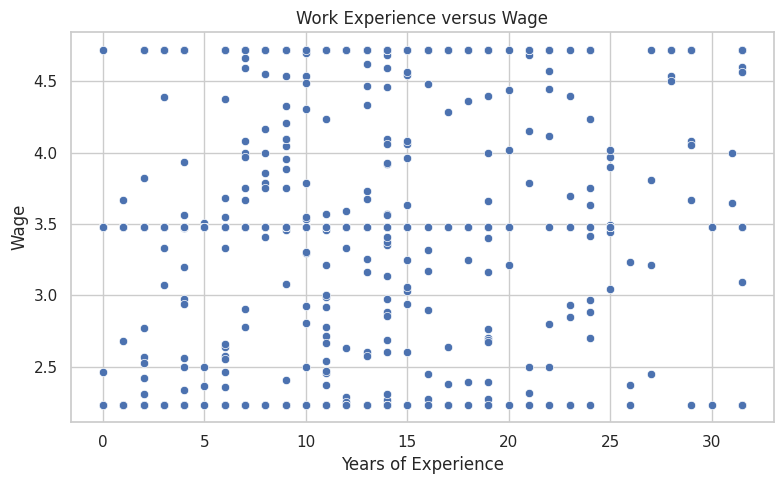

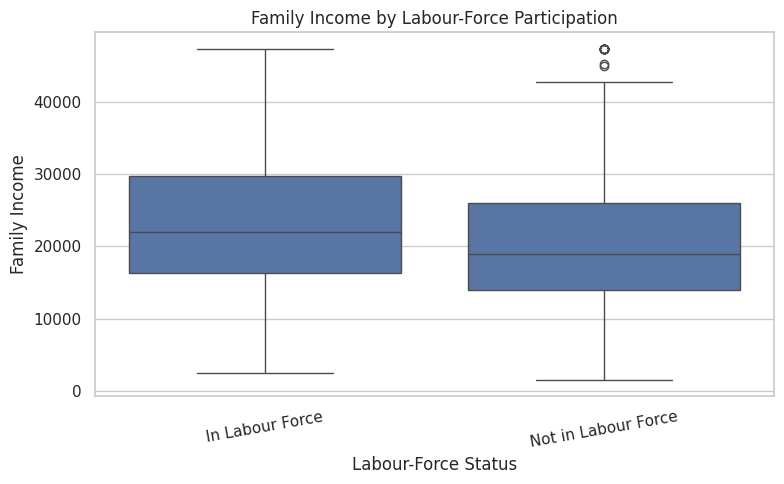

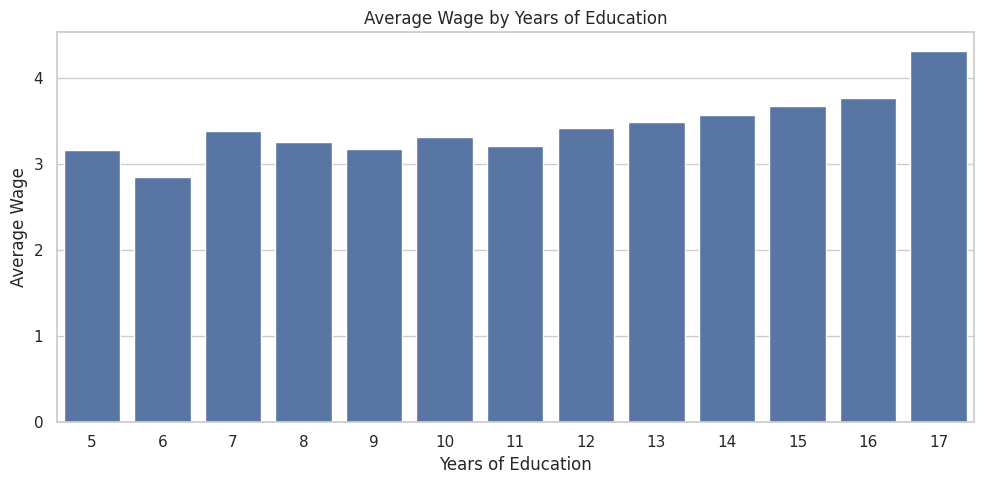

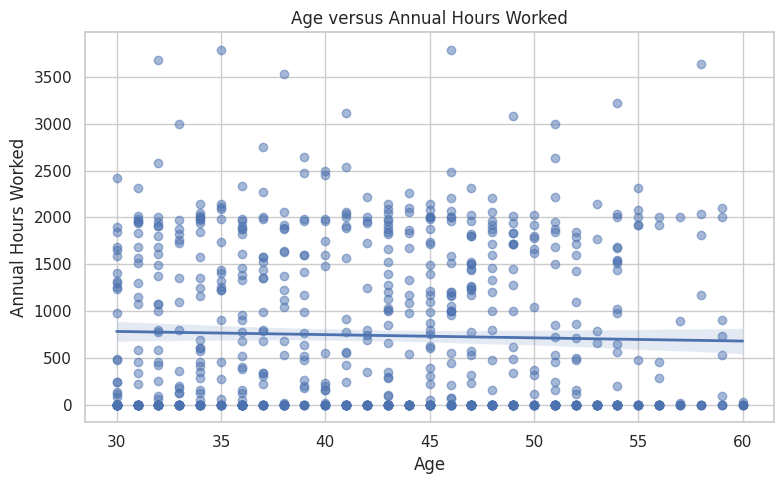

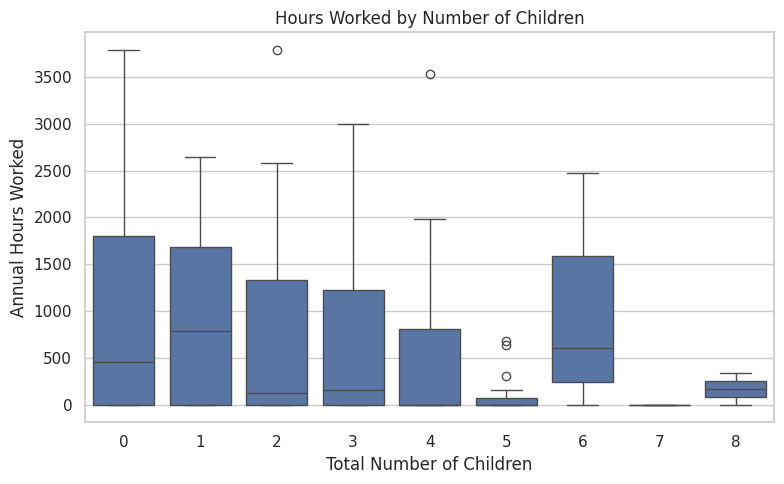

In [ ]:
# 7. BIVARIATE ANALYSIS
# Minimum three visualizations


# Visualization 1: Experience versus wage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_transformed,
    x="exper",
    y="wage"
)

plt.title("Work Experience versus Wage")
plt.xlabel("Years of Experience")
plt.ylabel("Wage")
plt.tight_layout()
plt.show()


# Visualization 2: Labour-force participation versus family income
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="labour_force_status",
    y="faminc"
)

plt.title("Family Income by Labour-Force Participation")
plt.xlabel("Labour-Force Status")
plt.ylabel("Family Income")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# Visualization 3: Education versus average wage
education_wage = (
    df_transformed
    .groupby("educ", as_index=False, observed=False)["wage"]
    .mean()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=education_wage,
    x="educ",
    y="wage"
)

plt.title("Average Wage by Years of Education")
plt.xlabel("Years of Education")
plt.ylabel("Average Wage")
plt.tight_layout()
plt.show()


# Visualization 4: Age versus hours worked
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_transformed,
    x="age",
    y="hours",
    scatter_kws={"alpha": 0.5},
    line_kws={"linewidth": 2}
)

plt.title("Age versus Annual Hours Worked")
plt.xlabel("Age")
plt.ylabel("Annual Hours Worked")
plt.tight_layout()
plt.show()


# Visualization 5: Number of children versus hours worked
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_transformed,
    x="total_children",
    y="hours"
)

plt.title("Hours Worked by Number of Children")
plt.xlabel("Total Number of Children")
plt.ylabel("Annual Hours Worked")
plt.tight_layout()
plt.show()


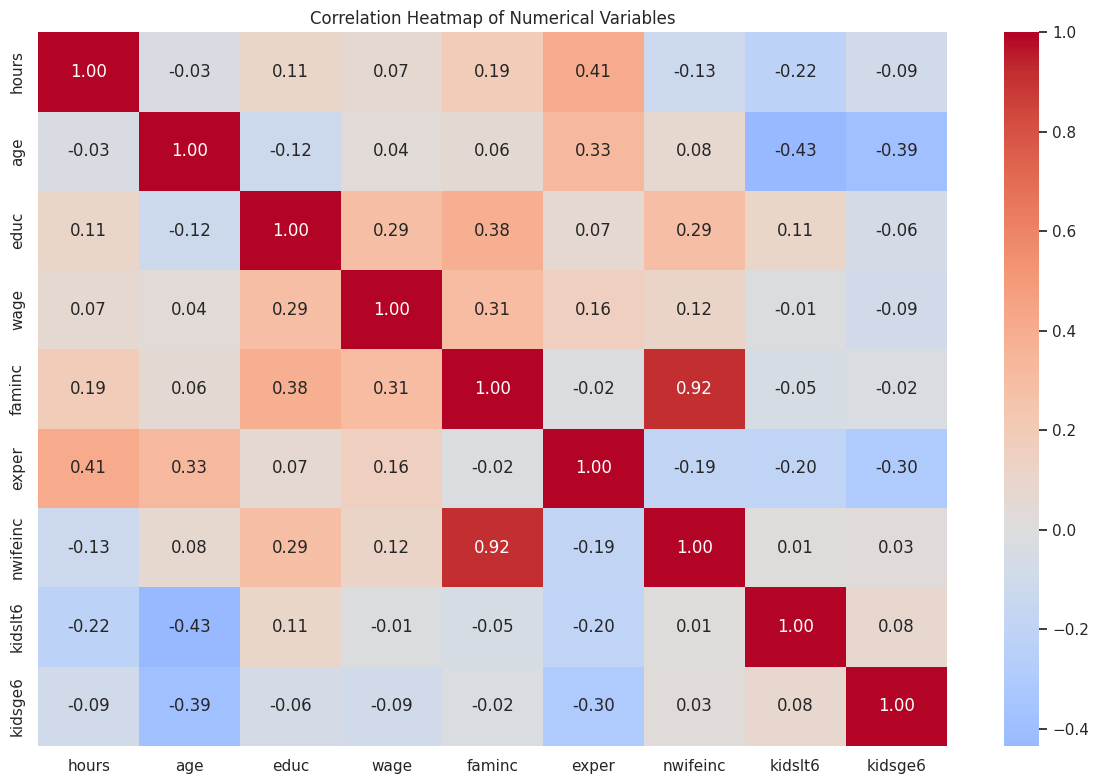

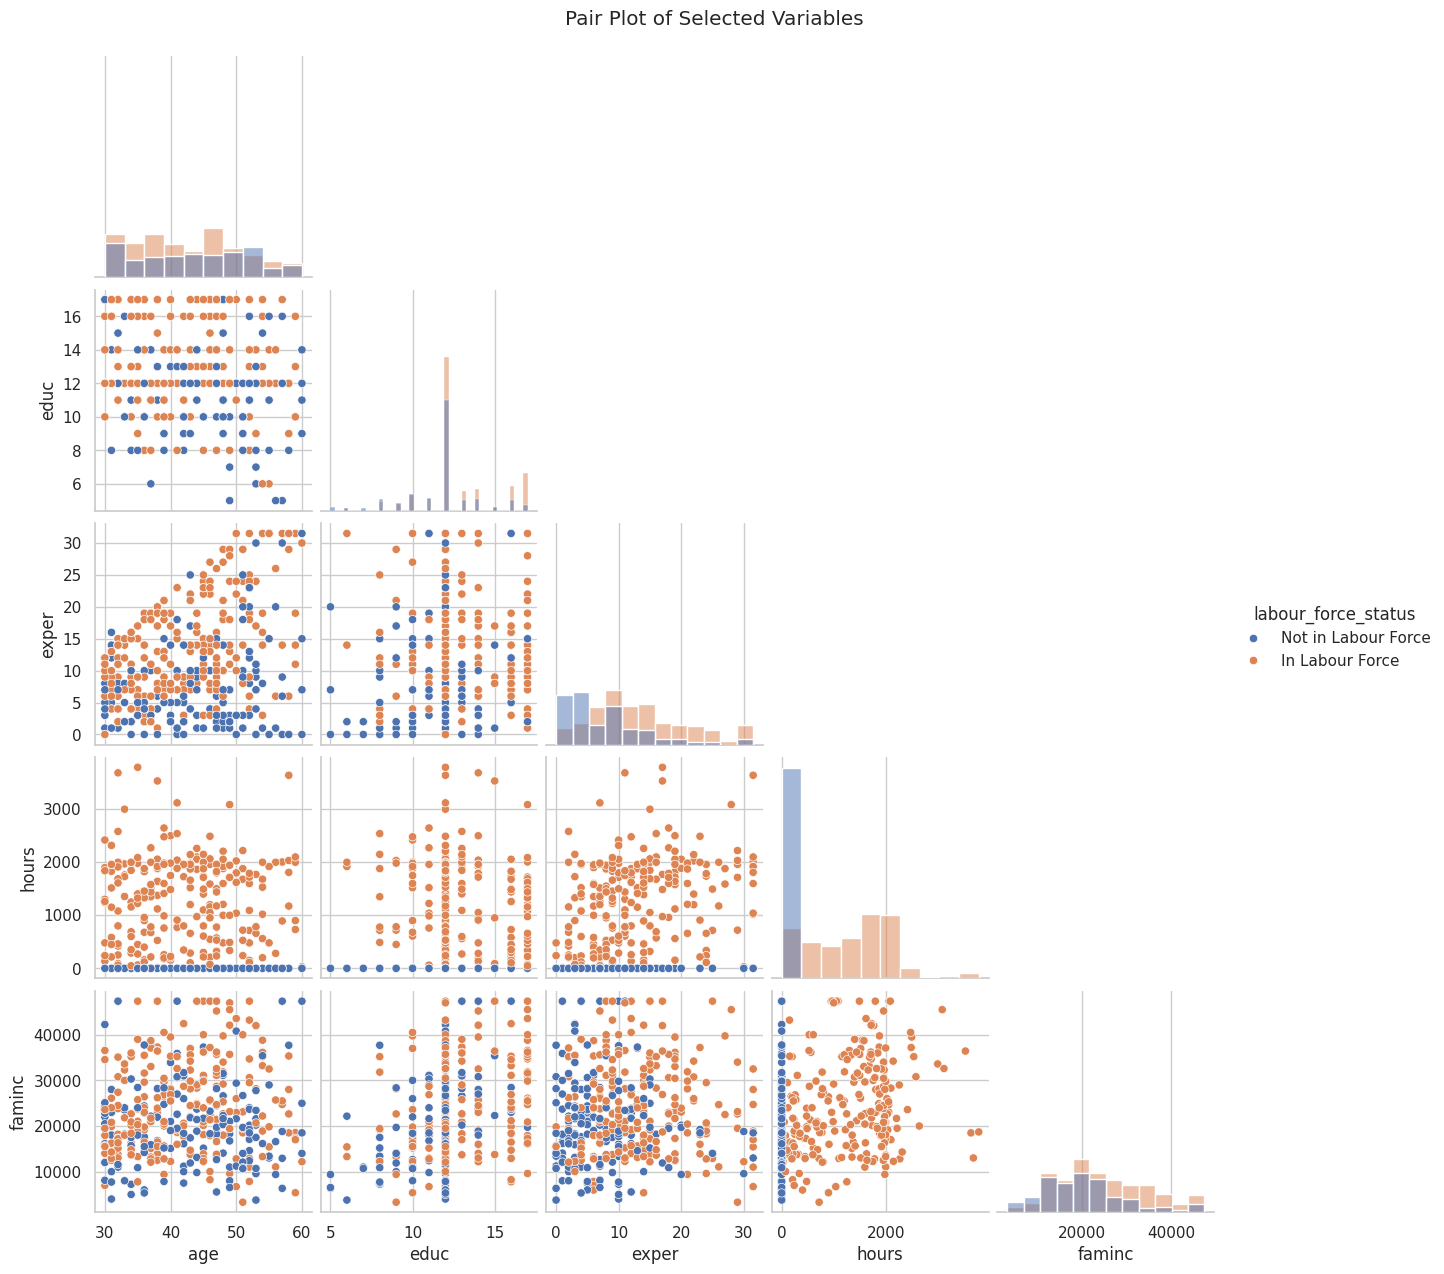

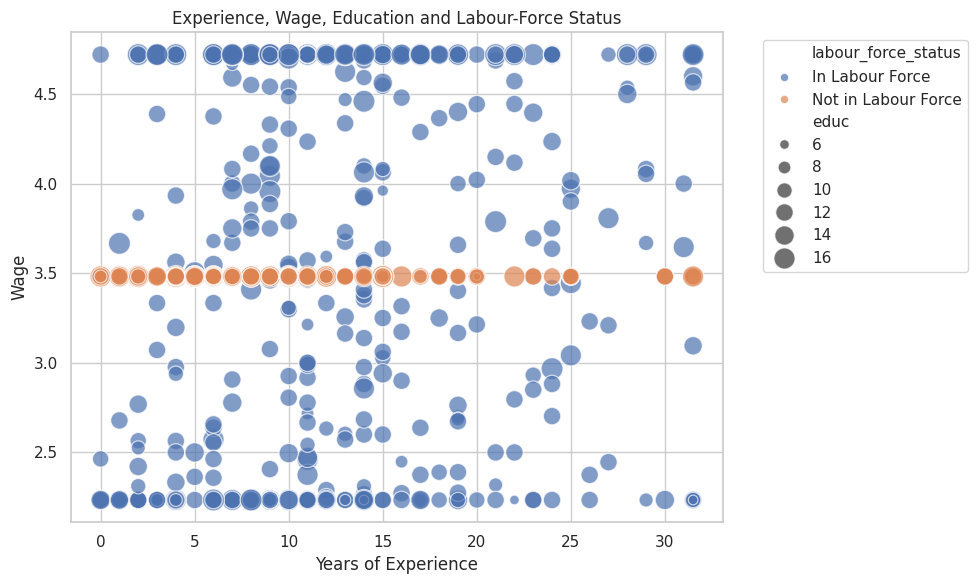

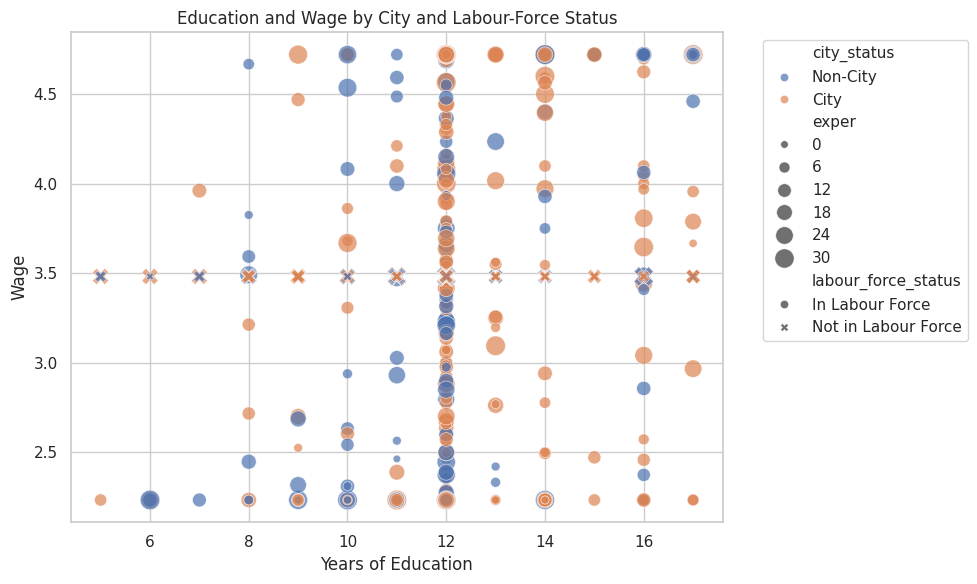

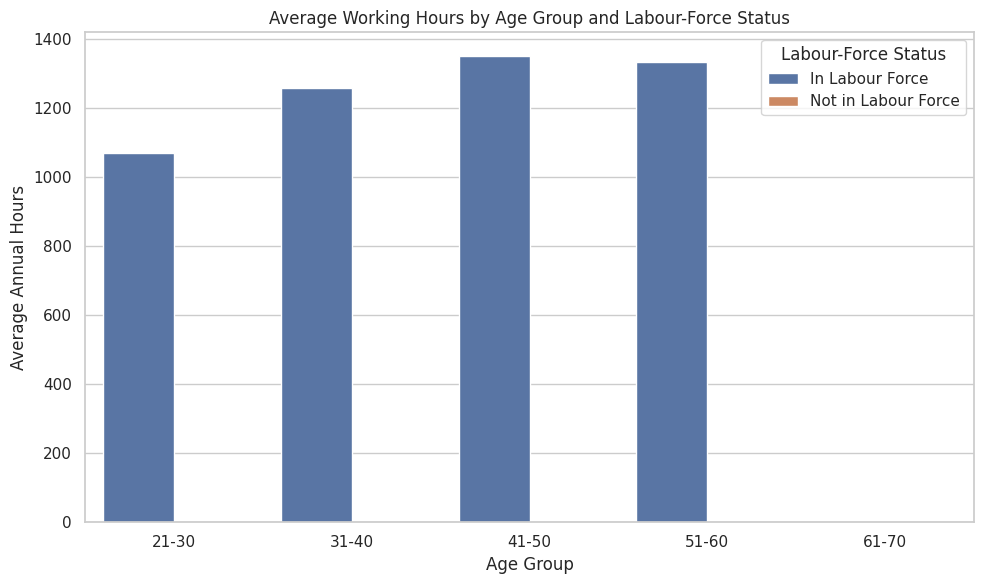

In [ ]:
# 8. MULTIVARIATE ANALYSIS
# Minimum three visualizations



# Visualization 1: Correlation heatmap
correlation_columns = [
    "hours",
    "age",
    "educ",
    "wage",
    "faminc",
    "exper",
    "nwifeinc",
    "kidslt6",
    "kidsge6"
]

available_correlation_columns = [
    column for column in correlation_columns
    if column in df_transformed.columns
]

correlation_matrix = df_transformed[
    available_correlation_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


# Visualization 2: Pair plot
pairplot_columns = [
    "age",
    "educ",
    "exper",
    "hours",
    "faminc",
    "labour_force_status"
]

pairplot_data = df_transformed[
    pairplot_columns
].sample(
    n=min(400, len(df_transformed)),
    random_state=42
)

sns.pairplot(
    pairplot_data,
    hue="labour_force_status",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pair Plot of Selected Variables",
    y=1.02
)

plt.show()


# Visualization 3: Multivariate scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_transformed,
    x="exper",
    y="wage",
    hue="labour_force_status",
    size="educ",
    sizes=(30, 250),
    alpha=0.7
)

plt.title(
    "Experience, Wage, Education and Labour-Force Status"
)

plt.xlabel("Years of Experience")
plt.ylabel("Wage")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# Visualization 4: Education and wage by city status
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_transformed,
    x="educ",
    y="wage",
    hue="city_status",
    style="labour_force_status",
    size="exper",
    sizes=(30, 200),
    alpha=0.7
)

plt.title(
    "Education and Wage by City and Labour-Force Status"
)

plt.xlabel("Years of Education")
plt.ylabel("Wage")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


# Visualization 5: Average hours by age group and labour status
age_hours = (
    df_transformed
    .groupby(
        ["age_group", "labour_force_status"],
        observed=False
    )["hours"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_hours,
    x="age_group",
    y="hours",
    hue="labour_force_status"
)

plt.title(
    "Average Working Hours by Age Group and Labour-Force Status"
)

plt.xlabel("Age Group")
plt.ylabel("Average Annual Hours")
plt.legend(title="Labour-Force Status")
plt.tight_layout()
plt.show()


In [1]:
#2 CAT 2 new 23BDS0018 PRATYAY MAJHI

## Google Colab is available in VS Code!
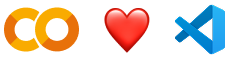

Try the new [Google Colab extension](https://marketplace.visualstudio.com/items?itemName=Google.colab) for Visual Studio Code. You can get up and running in just a few clicks:

*  In VS Code, open the ***Extensions*** view and search for 'Google Colab' to install.
*  Open the kernel selector by creating or opening any `.ipynb` notebook file in your local workspace and either running a cell or clicking the ***Select Kernel*** button in the top right.
*  Click ***Colab*** and then select your desired runtime, sign in with your Google account, and you're all set!

See more details in our [announcement blog here](https://developers.googleblog.com/google-colab-is-coming-to-vs-code).

## Access popular AI models via Google-Colab-AI Without an API Key
All users have access to most popular LLMs via the `google-colab-ai` Python library, and paid users have access to a wider selection of models. For more details, refer to the [getting started with google colab ai](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb).



In [18]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES AND LOAD DATASET
# Name   : PRATAY MAJHI
# Reg No : 23BDS0018
# ============================================================

# pandas is used for reading and manipulating datasets
import pandas as pd

# numpy is used for numerical calculations
import numpy as np

# matplotlib is used for creating plots
import matplotlib.pyplot as plt

# seaborn provides statistical visualization
import seaborn as sns

# Statistical functions
from scipy.stats import (
    chi2_contingency,
    pearsonr,
    spearmanr,
    probplot
)

# Machine learning and clustering libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture

# Hierarchical clustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Minimum Spanning Tree
from scipy.sparse.csgraph import minimum_spanning_tree

# Document clustering
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# ------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------

# Read the Mroz dataset from GitHub
PRATAY_MAJHI_23BDS0018 = pd.read_csv(
    "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv"
)

# Display first 5 observations
print("FIRST 5 ROWS")
print(PRATAY_MAJHI_23BDS0018.head())

# Display last 5 observations
print("\nLAST 5 ROWS")
print(PRATAY_MAJHI_23BDS0018.tail())

FIRST 5 ROWS
   rownames  inlf  hours  kidslt6  kidsge6  age  educ    wage  repwage  \
0         1     1   1610        1        0   32    12  3.3540     2.65   
1         2     1   1656        0        2   30    12  1.3889     2.65   
2         3     1   1980        1        3   35    12  4.5455     4.04   
3         4     1    456        0        3   34    12  1.0965     3.25   
4         5     1   1568        1        2   31    14  4.5918     3.60   

   hushrs  ...  faminc     mtr  motheduc  fatheduc  unem  city  exper  \
0    2708  ...   16310  0.7215        12         7   5.0     0     14   
1    2310  ...   21800  0.6615         7         7  11.0     1      5   
2    3072  ...   21040  0.6915        12         7   5.0     0     15   
3    1920  ...    7300  0.7815         7         7   5.0     0      6   
4    2000  ...   27300  0.6215        12        14   9.5     1      7   

    nwifeinc     lwage  expersq  
0  10.910060  1.210154      196  
1  19.499981  0.328512       25  
2

In [19]:
# ============================================================
# SECTION 2: BASIC DATASET INFORMATION
# ============================================================

# ------------------------------------------------------------
# SHAPE
# ------------------------------------------------------------

# shape returns:
# number of rows and number of columns

print("DATASET SHAPE")
print(PRATAY_MAJHI_23BDS0018.shape)


# ------------------------------------------------------------
# COLUMN NAMES
# ------------------------------------------------------------

print("\nCOLUMN NAMES")

for column_23BDS0018 in PRATAY_MAJHI_23BDS0018.columns:
    print(column_23BDS0018)


# ------------------------------------------------------------
# DATA TYPES
# ------------------------------------------------------------

print("\nDATA TYPES")
print(PRATAY_MAJHI_23BDS0018.dtypes)


# ------------------------------------------------------------
# INFORMATION
# ------------------------------------------------------------

print("\nDATASET INFORMATION")

# info() displays:
# - number of observations
# - column names
# - non-null values
# - data types

PRATAY_MAJHI_23BDS0018.info()


# ------------------------------------------------------------
# DESCRIPTIVE STATISTICS
# ------------------------------------------------------------

print("\nDESCRIPTIVE STATISTICS")

# describe() gives:
# count, mean, standard deviation,
# minimum, quartiles and maximum

print(
    PRATAY_MAJHI_23BDS0018.describe()
)

DATASET SHAPE
(753, 23)

COLUMN NAMES
rownames
inlf
hours
kidslt6
kidsge6
age
educ
wage
repwage
hushrs
husage
huseduc
huswage
faminc
mtr
motheduc
fatheduc
unem
city
exper
nwifeinc
lwage
expersq

DATA TYPES
rownames      int64
inlf          int64
hours         int64
kidslt6       int64
kidsge6       int64
age           int64
educ          int64
wage        float64
repwage     float64
hushrs        int64
husage        int64
huseduc       int64
huswage     float64
faminc        int64
mtr         float64
motheduc      int64
fatheduc      int64
unem        float64
city          int64
exper         int64
nwifeinc    float64
lwage       float64
expersq       int64
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 753 entries, 0 to 752
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  753 non-null    int64  
 1   inlf      753 non-null    int64  
 2   hours     753 non-null    int64  

MISSING VALUES
rownames      0
inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64


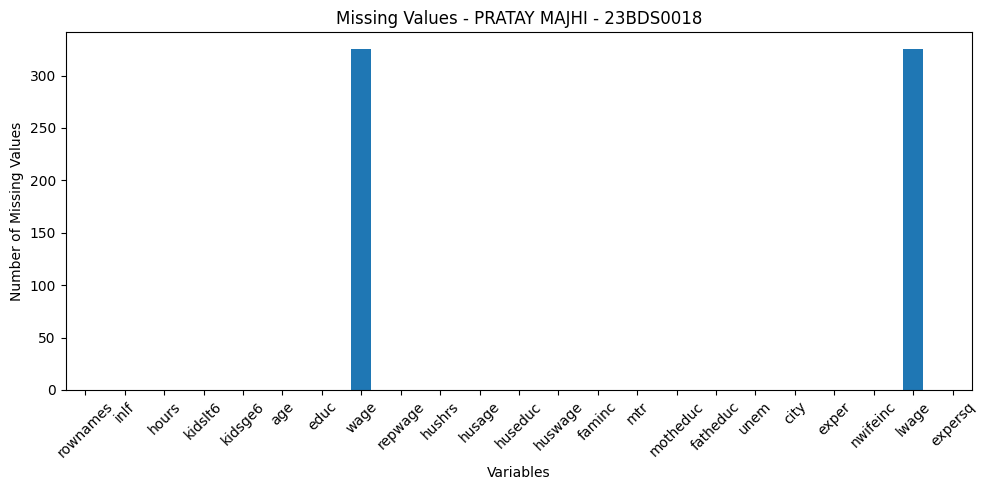

In [20]:
# ============================================================
# SECTION 3: MISSING VALUE ANALYSIS
# ============================================================

# Count missing values in every column
missing_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018.isnull().sum()
)

print("MISSING VALUES")
print(missing_23BDS0018)


# ------------------------------------------------------------
# PLOT MISSING VALUES
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

missing_23BDS0018.plot(
    kind="bar"
)

plt.title(
    "Missing Values - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Variables")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

MISSING VALUES
rownames      0
inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64


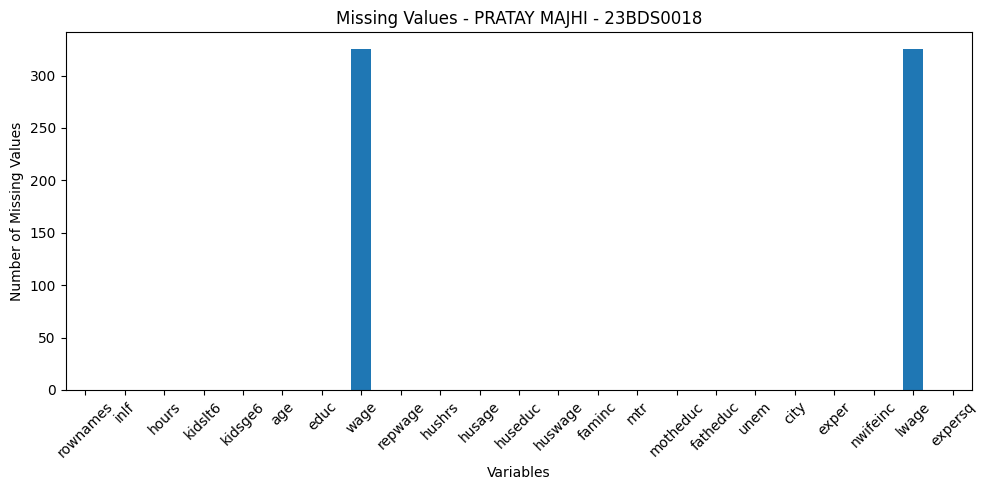

In [21]:
# ============================================================
# SECTION 3: MISSING VALUE ANALYSIS
# ============================================================

# Count missing values in every column
missing_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018.isnull().sum()
)

print("MISSING VALUES")
print(missing_23BDS0018)


# ------------------------------------------------------------
# PLOT MISSING VALUES
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

missing_23BDS0018.plot(
    kind="bar"
)

plt.title(
    "Missing Values - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Variables")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [22]:
# ============================================================
# SECTION 5: CATEGORICAL VARIABLE PREPARATION
# ============================================================

# ------------------------------------------------------------
# LABOR FORCE VARIABLE
# ------------------------------------------------------------

# Convert numerical coding into meaningful labels

if "inlf" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["inlf_label"] = (
        PRATAY_MAJHI_23BDS0018["inlf"]
        .map({
            0: "Not in Labor Force",
            1: "In Labor Force"
        })
    )


# ------------------------------------------------------------
# CITY VARIABLE
# ------------------------------------------------------------

if "city" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["city_label"] = (
        PRATAY_MAJHI_23BDS0018["city"]
        .map({
            0: "Rural",
            1: "Urban"
        })
    )


print(
    PRATAY_MAJHI_23BDS0018[
        ["inlf_label", "city_label"]
    ].head()
)

       inlf_label city_label
0  In Labor Force      Rural
1  In Labor Force      Urban
2  In Labor Force      Rural
3  In Labor Force      Rural
4  In Labor Force      Urban


rownames      0
inlf          0
hours         0
kidslt6       0
kidsge6       0
age           0
educ          0
wage        325
repwage       0
hushrs        0
husage        0
huseduc       0
huswage       0
faminc        0
mtr           0
motheduc      0
fatheduc      0
unem          0
city          0
exper         0
nwifeinc      0
lwage       325
expersq       0
dtype: int64


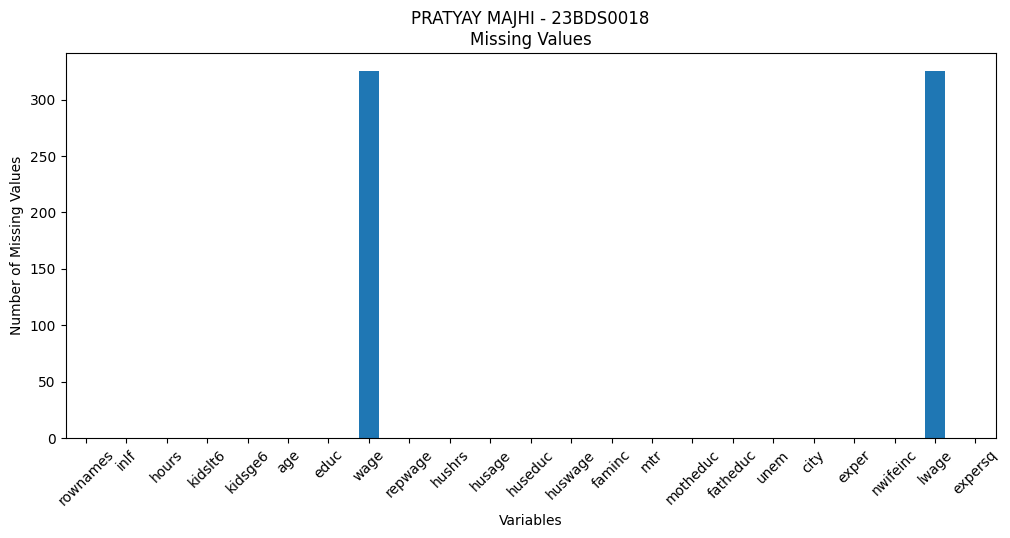

In [16]:
missing_23BDS0018 = PRATYAY_MAJHI_23BDS0018.isnull().sum()

print(missing_23BDS0018)
plt.figure(figsize=(12,5))

missing_23BDS0018.plot(kind="bar")

plt.title(
    "PRATYAY MAJHI - 23BDS0018\nMissing Values"
)

plt.xlabel("Variables")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.show()

In [23]:
# ============================================================
# SECTION 5: CATEGORICAL VARIABLE PREPARATION
# ============================================================

# ------------------------------------------------------------
# LABOR FORCE VARIABLE
# ------------------------------------------------------------

# Convert numerical coding into meaningful labels

if "inlf" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["inlf_label"] = (
        PRATAY_MAJHI_23BDS0018["inlf"]
        .map({
            0: "Not in Labor Force",
            1: "In Labor Force"
        })
    )


# ------------------------------------------------------------
# CITY VARIABLE
# ------------------------------------------------------------

if "city" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["city_label"] = (
        PRATAY_MAJHI_23BDS0018["city"]
        .map({
            0: "Rural",
            1: "Urban"
        })
    )


print(
    PRATAY_MAJHI_23BDS0018[
        ["inlf_label", "city_label"]
    ].head()
)

       inlf_label city_label
0  In Labor Force      Rural
1  In Labor Force      Urban
2  In Labor Force      Rural
3  In Labor Force      Rural
4  In Labor Force      Urban


In [24]:
# ============================================================
# SECTION 5: CATEGORICAL VARIABLE PREPARATION
# ============================================================

# ------------------------------------------------------------
# LABOR FORCE VARIABLE
# ------------------------------------------------------------

# Convert numerical coding into meaningful labels

if "inlf" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["inlf_label"] = (
        PRATAY_MAJHI_23BDS0018["inlf"]
        .map({
            0: "Not in Labor Force",
            1: "In Labor Force"
        })
    )


# ------------------------------------------------------------
# CITY VARIABLE
# ------------------------------------------------------------

if "city" in PRATAY_MAJHI_23BDS0018.columns:

    PRATAY_MAJHI_23BDS0018["city_label"] = (
        PRATAY_MAJHI_23BDS0018["city"]
        .map({
            0: "Rural",
            1: "Urban"
        })
    )


print(
    PRATAY_MAJHI_23BDS0018[
        ["inlf_label", "city_label"]
    ].head()
)

       inlf_label city_label
0  In Labor Force      Rural
1  In Labor Force      Urban
2  In Labor Force      Rural
3  In Labor Force      Rural
4  In Labor Force      Urban


MEAN OF HOURS
740.5763612217795


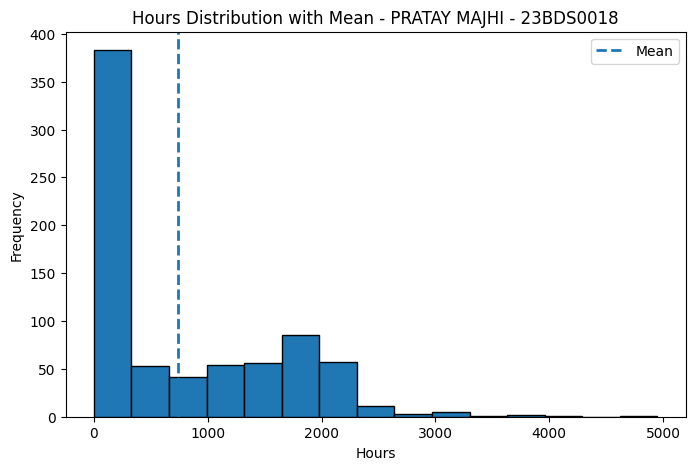

In [25]:
# ============================================================
# SECTION 6: 1-D ANALYSIS - MEAN
# Variable: HOURS
# ============================================================

# Remove missing values from hours
PRATAY_MAJHI_23BDS0018_hours = (
    PRATAY_MAJHI_23BDS0018["hours"]
    .dropna()
)


# ------------------------------------------------------------
# CALCULATE MEAN
# ------------------------------------------------------------

mean_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours.mean()
)

print("MEAN OF HOURS")
print(mean_23BDS0018)


# ------------------------------------------------------------
# HISTOGRAM
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    PRATAY_MAJHI_23BDS0018_hours,
    bins=15,
    edgecolor="black"
)

# Draw a vertical line at the mean
plt.axvline(
    mean_23BDS0018,
    linestyle="--",
    linewidth=2,
    label="Mean"
)

plt.title(
    "Hours Distribution with Mean - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")
plt.ylabel("Frequency")

plt.legend()

plt.show()

MEDIAN OF HOURS
288.0


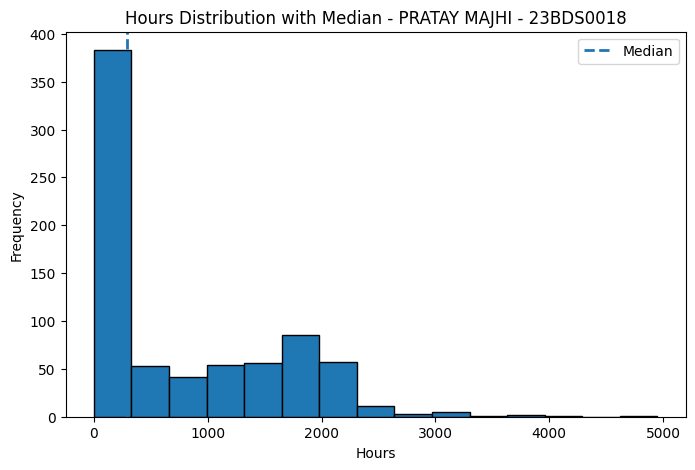

In [26]:
# ============================================================
# SECTION 7: 1-D ANALYSIS - MEDIAN
# ============================================================

# Calculate median
median_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours.median()
)

print("MEDIAN OF HOURS")
print(median_23BDS0018)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    PRATAY_MAJHI_23BDS0018_hours,
    bins=15,
    edgecolor="black"
)

# Draw median line
plt.axvline(
    median_23BDS0018,
    linestyle="--",
    linewidth=2,
    label="Median"
)

plt.title(
    "Hours Distribution with Median - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")
plt.ylabel("Frequency")

plt.legend()

plt.show()

MINIMUM: 0
MAXIMUM: 4950
RANGE: 4950


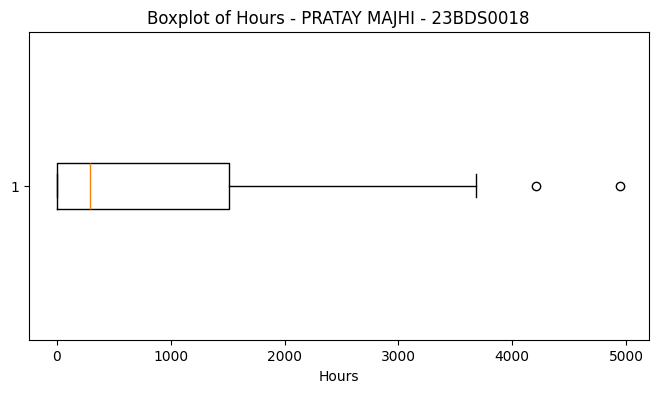

In [27]:
# ============================================================
# SECTION 10: MINIMUM, MAXIMUM AND RANGE
# ============================================================

minimum_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours.min()
)

maximum_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours.max()
)

range_23BDS0018 = (
    maximum_23BDS0018 -
    minimum_23BDS0018
)


print("MINIMUM:", minimum_23BDS0018)

print("MAXIMUM:", maximum_23BDS0018)

print("RANGE:", range_23BDS0018)


# ------------------------------------------------------------
# BOX PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

plt.boxplot(
    PRATAY_MAJHI_23BDS0018_hours,
    vert=False
)

plt.title(
    "Boxplot of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")

plt.show()

Q1 = 0.0
Q3 = 1516.0
IQR = 1516.0


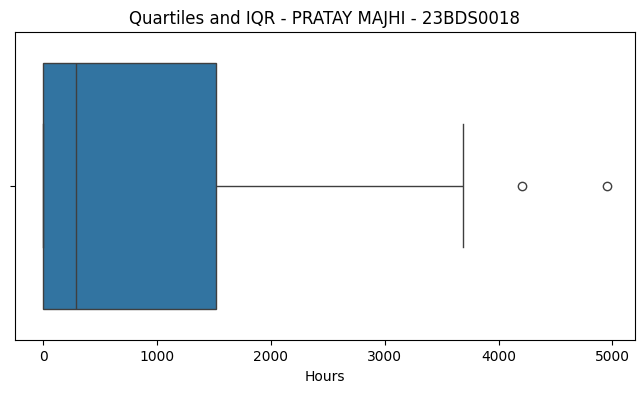

In [28]:
# ============================================================
# SECTION 11: QUARTILES AND IQR
# ============================================================

# First quartile = 25th percentile
Q1_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .quantile(0.25)
)

# Third quartile = 75th percentile
Q3_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .quantile(0.75)
)

# Interquartile range
IQR_23BDS0018 = (
    Q3_23BDS0018 -
    Q1_23BDS0018
)


print("Q1 =", Q1_23BDS0018)

print("Q3 =", Q3_23BDS0018)

print("IQR =", IQR_23BDS0018)


# ------------------------------------------------------------
# BOX PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=PRATAY_MAJHI_23BDS0018_hours
)

plt.title(
    "Quartiles and IQR - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")

plt.show()

Q1 = 0.0
Q3 = 1516.0
IQR = 1516.0


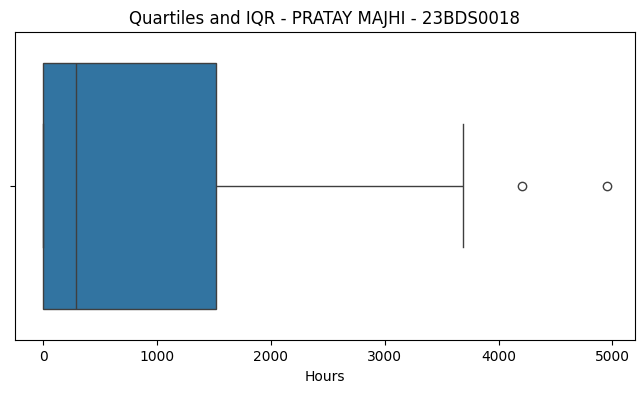

In [29]:
# ============================================================
# SECTION 11: QUARTILES AND IQR
# ============================================================

# First quartile = 25th percentile
Q1_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .quantile(0.25)
)

# Third quartile = 75th percentile
Q3_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .quantile(0.75)
)

# Interquartile range
IQR_23BDS0018 = (
    Q3_23BDS0018 -
    Q1_23BDS0018
)


print("Q1 =", Q1_23BDS0018)

print("Q3 =", Q3_23BDS0018)

print("IQR =", IQR_23BDS0018)


# ------------------------------------------------------------
# BOX PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=PRATAY_MAJHI_23BDS0018_hours
)

plt.title(
    "Quartiles and IQR - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")

plt.show()

LOWER LIMIT
-2274.0

UPPER LIMIT
3790.0

NUMBER OF OUTLIERS
2

OUTLIERS
36     4210
125    4950
Name: hours, dtype: int64


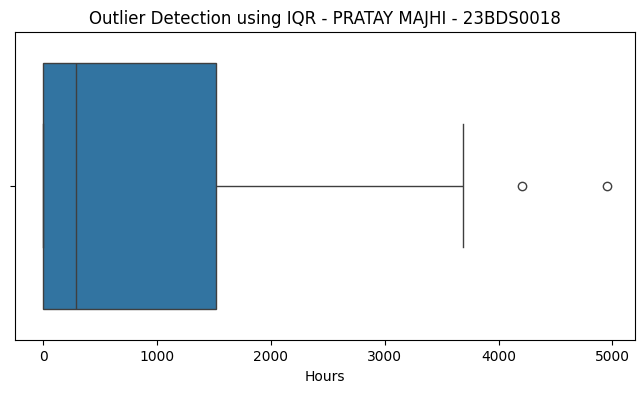

In [30]:
# ============================================================
# SECTION 12: OUTLIER DETECTION
# ============================================================

# Calculate lower boundary
lower_limit_23BDS0018 = (
    Q1_23BDS0018 -
    1.5 * IQR_23BDS0018
)

# Calculate upper boundary
upper_limit_23BDS0018 = (
    Q3_23BDS0018 +
    1.5 * IQR_23BDS0018
)


# Find observations below lower limit
# OR above upper limit

outliers_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours[
        (
            PRATAY_MAJHI_23BDS0018_hours
            < lower_limit_23BDS0018
        )
        |
        (
            PRATAY_MAJHI_23BDS0018_hours
            > upper_limit_23BDS0018
        )
    ]
)


print("LOWER LIMIT")
print(lower_limit_23BDS0018)

print("\nUPPER LIMIT")
print(upper_limit_23BDS0018)

print("\nNUMBER OF OUTLIERS")
print(len(outliers_23BDS0018))

print("\nOUTLIERS")
print(outliers_23BDS0018)


# ------------------------------------------------------------
# BOX PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=PRATAY_MAJHI_23BDS0018_hours
)

plt.title(
    "Outlier Detection using IQR - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")

plt.show()

SKEWNESS
0.9243738789896253


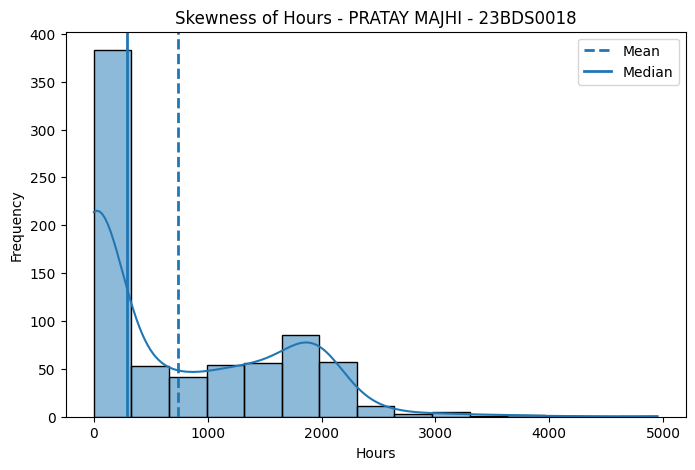

In [31]:
# ============================================================
# SECTION 13: SKEWNESS
# ============================================================

# skew() calculates asymmetry of the distribution

skewness_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .skew()
)

print("SKEWNESS")
print(skewness_23BDS0018)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    PRATAY_MAJHI_23BDS0018_hours,
    kde=True
)

plt.axvline(
    mean_23BDS0018,
    linestyle="--",
    linewidth=2,
    label="Mean"
)

plt.axvline(
    median_23BDS0018,
    linestyle="-",
    linewidth=2,
    label="Median"
)

plt.title(
    "Skewness of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")
plt.ylabel("Frequency")

plt.legend()

plt.show()

KURTOSIS
0.20325353153335524


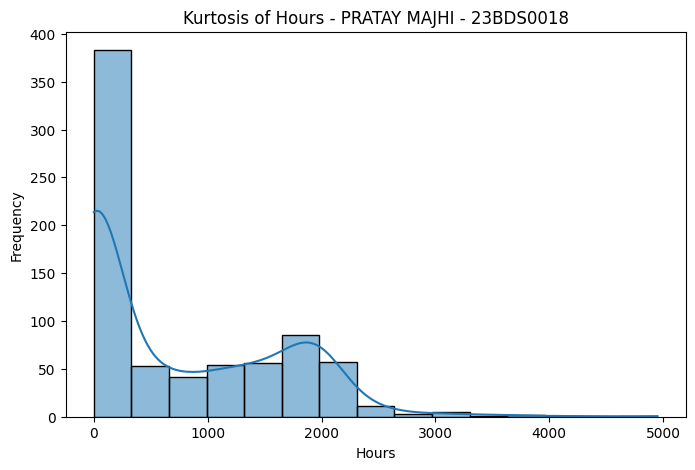

In [32]:
# ============================================================
# SECTION 14: KURTOSIS
# ============================================================

# kurt() measures the shape/tail behavior
# of the distribution.

kurtosis_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018_hours
    .kurt()
)

print("KURTOSIS")
print(kurtosis_23BDS0018)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    PRATAY_MAJHI_23BDS0018_hours,
    kde=True
)

plt.title(
    "Kurtosis of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Hours")
plt.ylabel("Frequency")

plt.show()

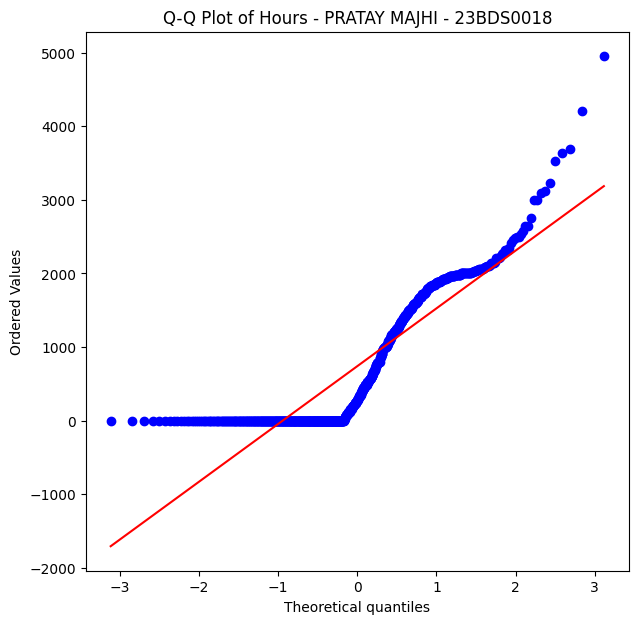

In [33]:
# ============================================================
# SECTION 16: Q-Q PLOT
# ============================================================

# Q-Q plot compares the observed distribution
# with a theoretical normal distribution.

plt.figure(figsize=(7, 7))

probplot(
    PRATAY_MAJHI_23BDS0018_hours,
    dist="norm",
    plot=plt
)

plt.title(
    "Q-Q Plot of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.show()

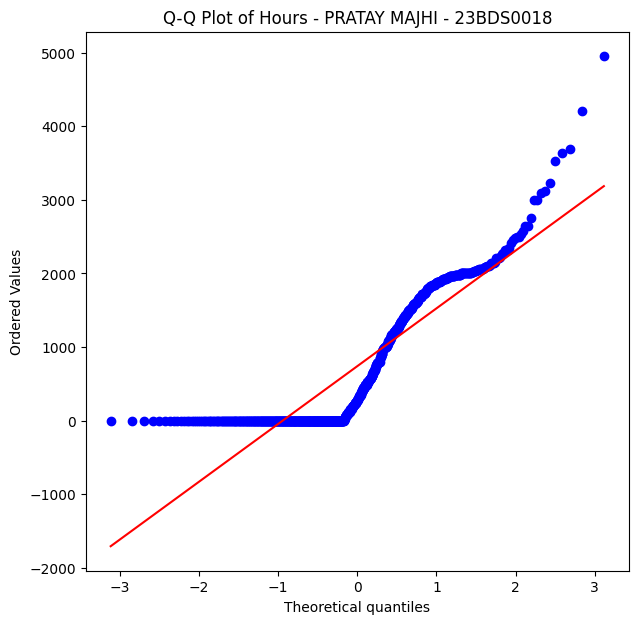

In [34]:
# ============================================================
# SECTION 16: Q-Q PLOT
# ============================================================

# Q-Q plot compares the observed distribution
# with a theoretical normal distribution.

plt.figure(figsize=(7, 7))

probplot(
    PRATAY_MAJHI_23BDS0018_hours,
    dist="norm",
    plot=plt
)

plt.title(
    "Q-Q Plot of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.show()

FREQUENCY DISTRIBUTION
hours
(-4.95, 495.0]      412
(495.0, 990.0]       65
(990.0, 1485.0]      79
(1485.0, 1980.0]    119
(1980.0, 2475.0]     60
(2475.0, 2970.0]      8
(2970.0, 3465.0]      5
(3465.0, 3960.0]      3
(3960.0, 4455.0]      1
(4455.0, 4950.0]      1
Name: count, dtype: int64


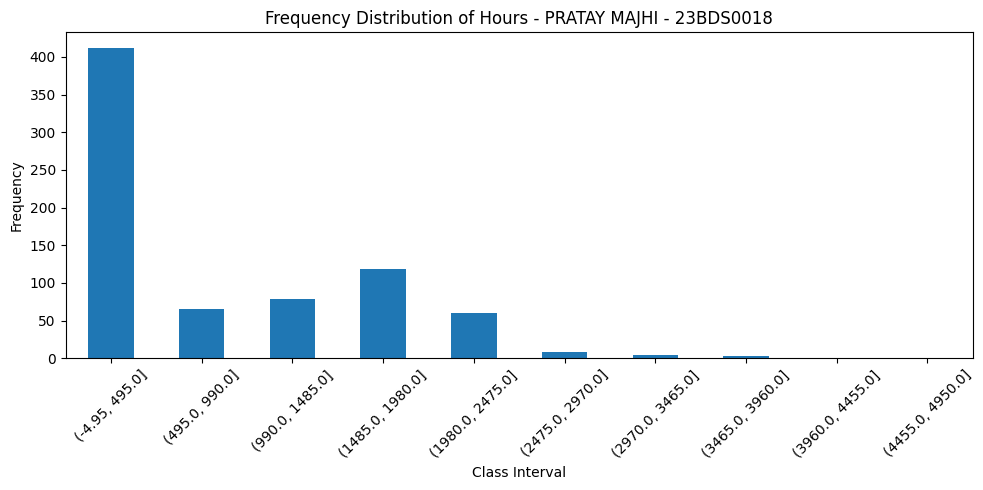

In [35]:
# ============================================================
# SECTION 17: FREQUENCY DISTRIBUTION
# ============================================================

# Divide the hours variable into 10 class intervals.

hours_frequency_23BDS0018 = (
    pd.cut(
        PRATAY_MAJHI_23BDS0018_hours,
        bins=10
    )
    .value_counts()
    .sort_index()
)

print("FREQUENCY DISTRIBUTION")

print(
    hours_frequency_23BDS0018
)


# ------------------------------------------------------------
# BAR PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

hours_frequency_23BDS0018.plot(
    kind="bar"
)

plt.title(
    "Frequency Distribution of Hours - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Class Interval")
plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

              Class  Frequency  Midpoint
0    (-4.95, 495.0]        412   245.025
1    (495.0, 990.0]         65   742.500
2   (990.0, 1485.0]         79  1237.500
3  (1485.0, 1980.0]        119  1732.500
4  (1980.0, 2475.0]         60  2227.500
5  (2475.0, 2970.0]          8  2722.500
6  (2970.0, 3465.0]          5  3217.500
7  (3465.0, 3960.0]          3  3712.500
8  (3960.0, 4455.0]          1  4207.500
9  (4455.0, 4950.0]          1  4702.500


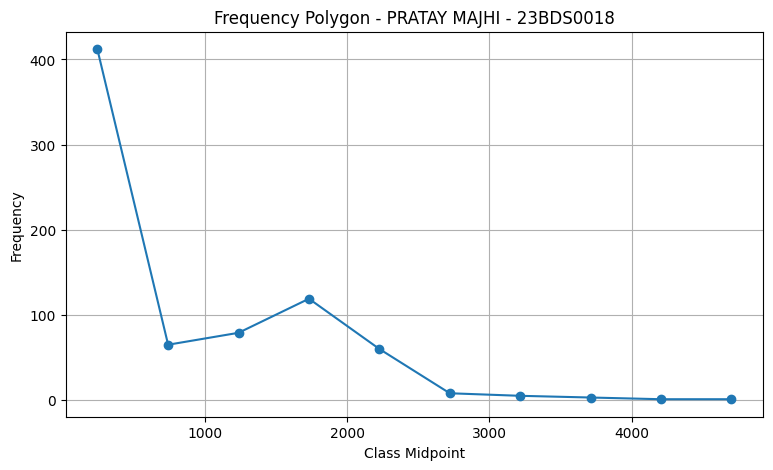

In [36]:
# ============================================================
# SECTION 18: FREQUENCY POLYGON
# ============================================================

# Convert frequency Series into DataFrame

frequency_table_23BDS0018 = (
    hours_frequency_23BDS0018
    .reset_index()
)

frequency_table_23BDS0018.columns = [
    "Class",
    "Frequency"
]


# Calculate class midpoint
frequency_table_23BDS0018["Midpoint"] = (
    frequency_table_23BDS0018["Class"]
    .apply(
        lambda x:
        (x.left + x.right) / 2
    )
)


print(frequency_table_23BDS0018)


# ------------------------------------------------------------
# FREQUENCY POLYGON
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    frequency_table_23BDS0018["Midpoint"],
    frequency_table_23BDS0018["Frequency"],
    marker="o"
)

plt.title(
    "Frequency Polygon - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Class Midpoint")
plt.ylabel("Frequency")

plt.grid()

plt.show()

              Class  Frequency  Midpoint  Cumulative_Frequency
0    (-4.95, 495.0]        412   245.025                   412
1    (495.0, 990.0]         65   742.500                   477
2   (990.0, 1485.0]         79  1237.500                   556
3  (1485.0, 1980.0]        119  1732.500                   675
4  (1980.0, 2475.0]         60  2227.500                   735
5  (2475.0, 2970.0]          8  2722.500                   743
6  (2970.0, 3465.0]          5  3217.500                   748
7  (3465.0, 3960.0]          3  3712.500                   751
8  (3960.0, 4455.0]          1  4207.500                   752
9  (4455.0, 4950.0]          1  4702.500                   753


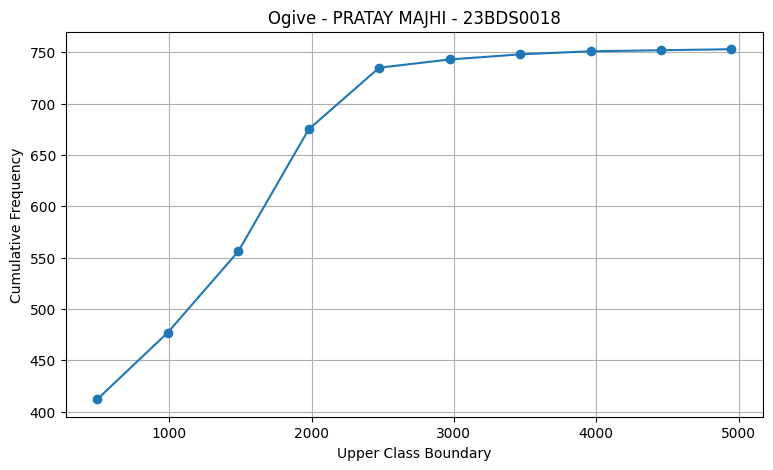

In [37]:
# ============================================================
# SECTION 19: OGIVE
# ============================================================

# Calculate cumulative frequency

frequency_table_23BDS0018[
    "Cumulative_Frequency"
] = (
    frequency_table_23BDS0018[
        "Frequency"
    ]
    .cumsum()
)


print(
    frequency_table_23BDS0018
)


# ------------------------------------------------------------
# OGIVE
# ------------------------------------------------------------

# For a less-than ogive we use
# the upper class boundary.

upper_boundaries_23BDS0018 = (
    frequency_table_23BDS0018["Class"]
    .apply(lambda x: x.right)
)


plt.figure(figsize=(9, 5))

plt.plot(
    upper_boundaries_23BDS0018,
    frequency_table_23BDS0018[
        "Cumulative_Frequency"
    ],
    marker="o"
)

plt.title(
    "Ogive - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Upper Class Boundary")
plt.ylabel("Cumulative Frequency")

plt.grid()

plt.show()

CONTINGENCY TABLE
city    0    1
inlf          
0     115  210
1     154  274


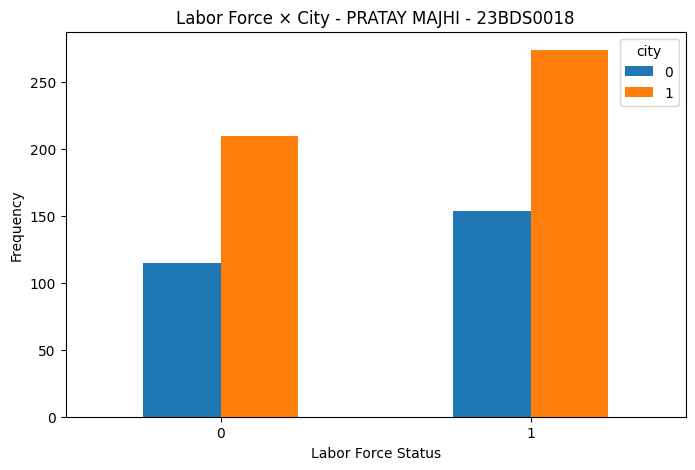

In [38]:
# ============================================================
# SECTION 20: 2-D CATEGORICAL ANALYSIS
# inlf × city
# ============================================================

# Create contingency table

table_23BDS0018 = pd.crosstab(
    PRATAY_MAJHI_23BDS0018["inlf"],
    PRATAY_MAJHI_23BDS0018["city"]
)

print("CONTINGENCY TABLE")

print(
    table_23BDS0018
)


# ------------------------------------------------------------
# BAR PLOT
# ------------------------------------------------------------

table_23BDS0018.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Labor Force × City - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Labor Force Status")
plt.ylabel("Frequency")

plt.xticks(rotation=0)

plt.show()

ROW PROFILE
city         0         1
inlf                    
0     0.353846  0.646154
1     0.359813  0.640187


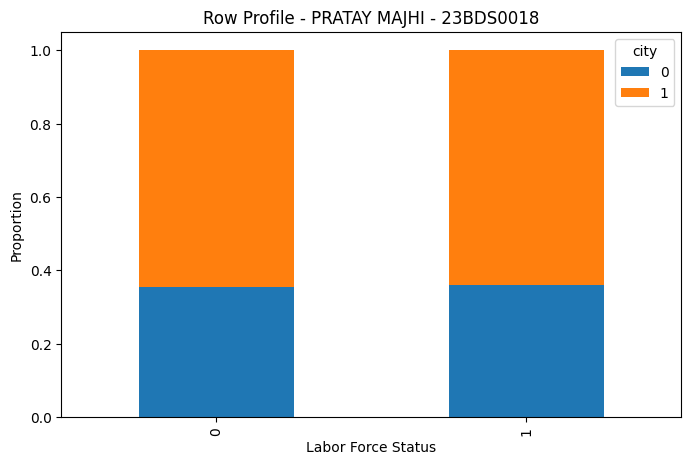

In [39]:
# ============================================================
# SECTION 21: ROW PROFILE
# ============================================================

# Divide every row by its row total.

row_profile_23BDS0018 = (
    table_23BDS0018
    .div(
        table_23BDS0018.sum(axis=1),
        axis=0
    )
)

print("ROW PROFILE")

print(
    row_profile_23BDS0018
)


# ------------------------------------------------------------
# STACKED BAR PLOT
# ------------------------------------------------------------

row_profile_23BDS0018.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title(
    "Row Profile - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Labor Force Status")
plt.ylabel("Proportion")

plt.show()

COLUMN PROFILE
city         0         1
inlf                    
0     0.427509  0.433884
1     0.572491  0.566116


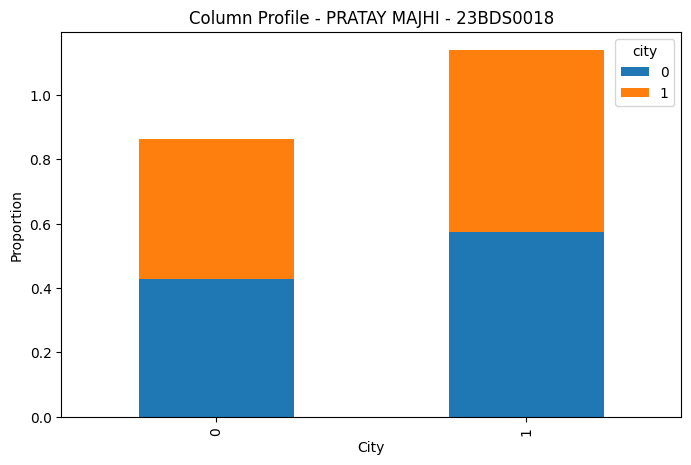

In [40]:
# ============================================================
# SECTION 22: COLUMN PROFILE
# ============================================================

# Divide every column by its column total.

column_profile_23BDS0018 = (
    table_23BDS0018
    .div(
        table_23BDS0018.sum(axis=0),
        axis=1
    )
)

print("COLUMN PROFILE")

print(
    column_profile_23BDS0018
)


# ------------------------------------------------------------
# STACKED BAR PLOT
# ------------------------------------------------------------

column_profile_23BDS0018.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title(
    "Column Profile - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("City")
plt.ylabel("Proportion")

plt.show()

COLUMN PROFILE
city         0         1
inlf                    
0     0.427509  0.433884
1     0.572491  0.566116


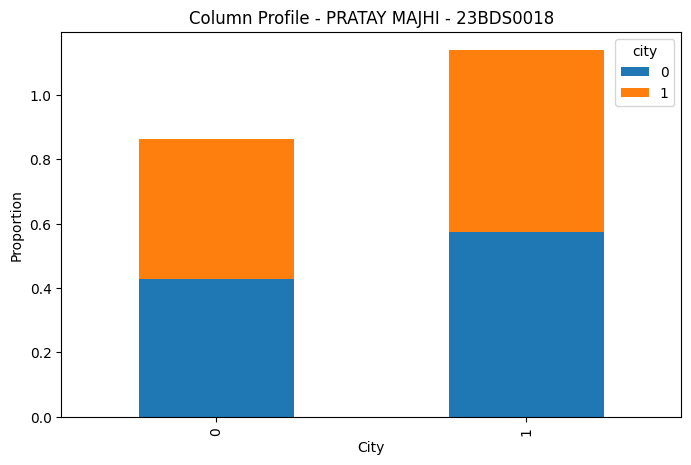

In [41]:
# ============================================================
# SECTION 22: COLUMN PROFILE
# ============================================================

# Divide every column by its column total.

column_profile_23BDS0018 = (
    table_23BDS0018
    .div(
        table_23BDS0018.sum(axis=0),
        axis=1
    )
)

print("COLUMN PROFILE")

print(
    column_profile_23BDS0018
)


# ------------------------------------------------------------
# STACKED BAR PLOT
# ------------------------------------------------------------

column_profile_23BDS0018.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title(
    "Column Profile - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("City")
plt.ylabel("Proportion")

plt.show()

RELATIVE FREQUENCY
city         0         1
inlf                    
0     0.152722  0.278884
1     0.204515  0.363878


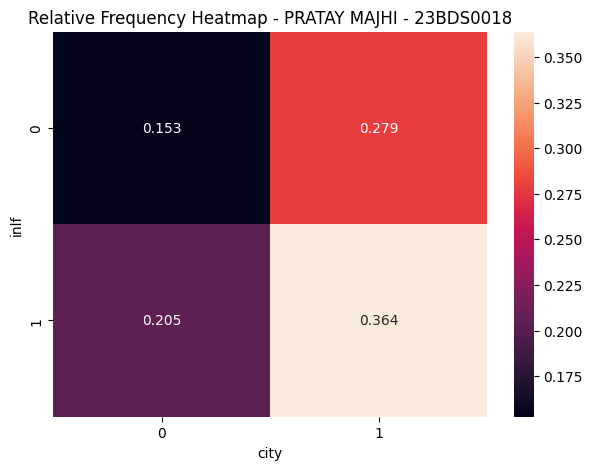

In [42]:
# ============================================================
# SECTION 23: RELATIVE FREQUENCY
# ============================================================

# Divide every cell by total number of observations.

relative_frequency_23BDS0018 = (
    table_23BDS0018 /
    table_23BDS0018.values.sum()
)

print("RELATIVE FREQUENCY")

print(
    relative_frequency_23BDS0018
)


# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    relative_frequency_23BDS0018,
    annot=True,
    fmt=".3f"
)

plt.title(
    "Relative Frequency Heatmap - PRATAY MAJHI - 23BDS0018"
)

plt.show()

CHI-SQUARE STATISTIC
0.008551155172031888

P-VALUE
0.926322674133866

DEGREES OF FREEDOM
1

EXPECTED FREQUENCIES
city           0           1
inlf                        
0     116.102258  208.897742
1     152.897742  275.102258


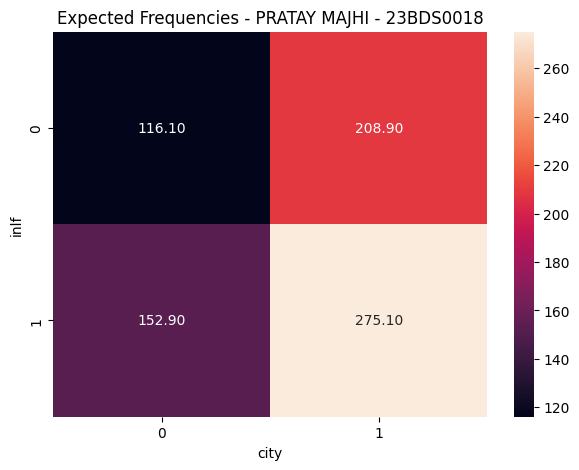


Decision: Fail to Reject H0
There is insufficient statistical evidence of an association between the variables.


In [43]:
# ============================================================
# SECTION 24: CHI-SQUARE TEST OF INDEPENDENCE
# ============================================================

# H0:
# The two categorical variables are independent.

# H1:
# The two categorical variables are associated.

chi2_23BDS0018, p_23BDS0018, dof_23BDS0018, expected_23BDS0018 = (
    chi2_contingency(
        table_23BDS0018
    )
)


print("CHI-SQUARE STATISTIC")
print(chi2_23BDS0018)

print("\nP-VALUE")
print(p_23BDS0018)

print("\nDEGREES OF FREEDOM")
print(dof_23BDS0018)


# ------------------------------------------------------------
# EXPECTED FREQUENCIES
# ------------------------------------------------------------

expected_table_23BDS0018 = pd.DataFrame(
    expected_23BDS0018,
    index=table_23BDS0018.index,
    columns=table_23BDS0018.columns
)

print("\nEXPECTED FREQUENCIES")

print(
    expected_table_23BDS0018
)


# ------------------------------------------------------------
# EXPECTED FREQUENCY HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    expected_table_23BDS0018,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Expected Frequencies - PRATAY MAJHI - 23BDS0018"
)

plt.show()


# ------------------------------------------------------------
# DECISION
# ------------------------------------------------------------

alpha_23BDS0018 = 0.05

if p_23BDS0018 < alpha_23BDS0018:

    print(
        "\nDecision: Reject H0"
    )

    print(
        "There is statistical evidence of an association "
        "between the two categorical variables."
    )

else:

    print(
        "\nDecision: Fail to Reject H0"
    )

    print(
        "There is insufficient statistical evidence "
        "of an association between the variables."
    )

CHI-SQUARE STATISTIC
0.008551155172031888

P-VALUE
0.926322674133866

DEGREES OF FREEDOM
1

EXPECTED FREQUENCIES
city           0           1
inlf                        
0     116.102258  208.897742
1     152.897742  275.102258


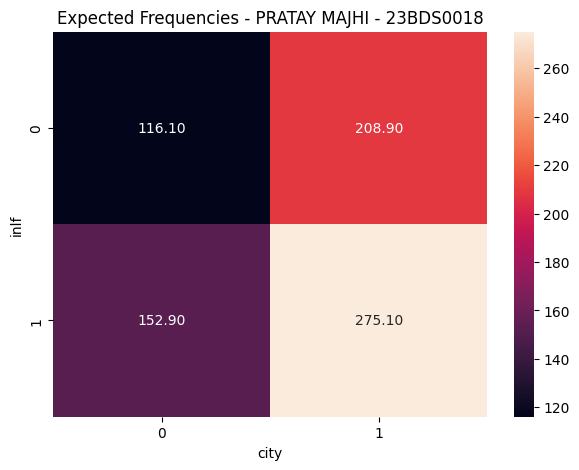


Decision: Fail to Reject H0
There is insufficient statistical evidence of an association between the variables.


In [44]:
# ============================================================
# SECTION 24: CHI-SQUARE TEST OF INDEPENDENCE
# ============================================================

# H0:
# The two categorical variables are independent.

# H1:
# The two categorical variables are associated.

chi2_23BDS0018, p_23BDS0018, dof_23BDS0018, expected_23BDS0018 = (
    chi2_contingency(
        table_23BDS0018
    )
)


print("CHI-SQUARE STATISTIC")
print(chi2_23BDS0018)

print("\nP-VALUE")
print(p_23BDS0018)

print("\nDEGREES OF FREEDOM")
print(dof_23BDS0018)


# ------------------------------------------------------------
# EXPECTED FREQUENCIES
# ------------------------------------------------------------

expected_table_23BDS0018 = pd.DataFrame(
    expected_23BDS0018,
    index=table_23BDS0018.index,
    columns=table_23BDS0018.columns
)

print("\nEXPECTED FREQUENCIES")

print(
    expected_table_23BDS0018
)


# ------------------------------------------------------------
# EXPECTED FREQUENCY HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    expected_table_23BDS0018,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Expected Frequencies - PRATAY MAJHI - 23BDS0018"
)

plt.show()


# ------------------------------------------------------------
# DECISION
# ------------------------------------------------------------

alpha_23BDS0018 = 0.05

if p_23BDS0018 < alpha_23BDS0018:

    print(
        "\nDecision: Reject H0"
    )

    print(
        "There is statistical evidence of an association "
        "between the two categorical variables."
    )

else:

    print(
        "\nDecision: Fail to Reject H0"
    )

    print(
        "There is insufficient statistical evidence "
        "of an association between the variables."
    )

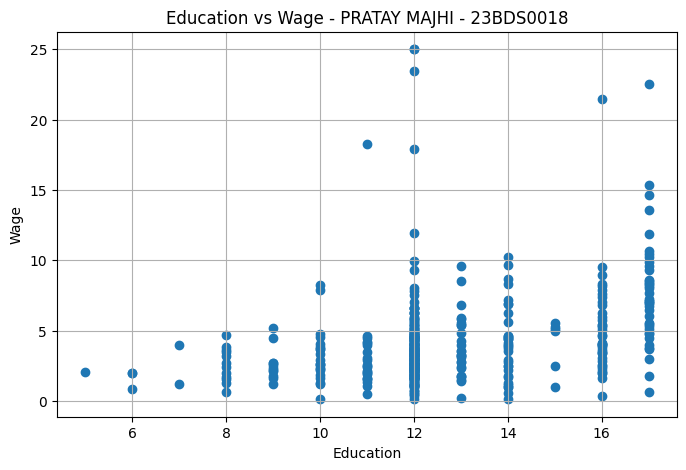

In [45]:
# ============================================================
# SECTION 25: 2-D QUANTITATIVE ANALYSIS
# Education × Wage
# ============================================================

education_wage_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        ["educ", "wage"]
    ]
    .dropna()
)


# ------------------------------------------------------------
# SCATTER PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    education_wage_23BDS0018["educ"],
    education_wage_23BDS0018["wage"]
)

plt.title(
    "Education vs Wage - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Education")
plt.ylabel("Wage")

plt.grid()

plt.show()

PEARSON CORRELATION
0.3419544357242256

P-VALUE
3.4859830946529394e-13


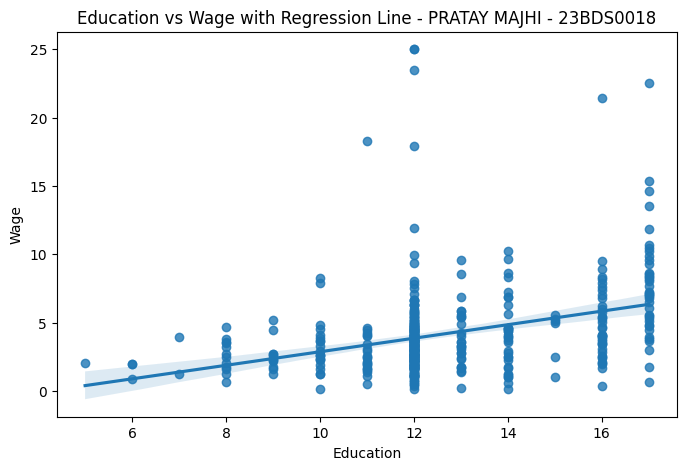

In [46]:
# ============================================================
# SECTION 26: PEARSON CORRELATION
# ============================================================

# Pearson correlation measures linear association.

pearson_23BDS0018, pearson_p_23BDS0018 = pearsonr(
    education_wage_23BDS0018["educ"],
    education_wage_23BDS0018["wage"]
)


print("PEARSON CORRELATION")
print(pearson_23BDS0018)

print("\nP-VALUE")
print(pearson_p_23BDS0018)


# ------------------------------------------------------------
# REGRESSION PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.regplot(
    data=education_wage_23BDS0018,
    x="educ",
    y="wage"
)

plt.title(
    "Education vs Wage with Regression Line - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Education")
plt.ylabel("Wage")

plt.show()

In [47]:
# ============================================================
# SECTION 27: SPEARMAN CORRELATION
# ============================================================

# Spearman correlation measures monotonic association
# using ranks rather than raw values.

spearman_23BDS0018, spearman_p_23BDS0018 = spearmanr(
    education_wage_23BDS0018["educ"],
    education_wage_23BDS0018["wage"]
)


print("SPEARMAN CORRELATION")
print(spearman_23BDS0018)

print("\nP-VALUE")
print(spearman_p_23BDS0018)

SPEARMAN CORRELATION
0.3843842234278303

P-VALUE
1.6113342440708987e-16


CORRELATION MATRIX
          rownames      inlf     hours   kidslt6   kidsge6       age  \
rownames  1.000000 -0.857886 -0.638588  0.170071  0.016401  0.053285   
inlf     -0.857886  1.000000  0.741145 -0.213749 -0.002424 -0.080498   
hours    -0.638588  0.741145  1.000000 -0.222063 -0.090632 -0.033114   
kidslt6   0.170071 -0.213749 -0.222063  1.000000  0.084160 -0.433949   
kidsge6   0.016401 -0.002424 -0.090632  0.084160  1.000000 -0.385411   
age       0.053285 -0.080498 -0.033114 -0.433949 -0.385411  1.000000   
educ     -0.160816  0.187353  0.105960  0.108690 -0.058899 -0.120223   
wage      0.073182       NaN -0.097628  0.031423 -0.079228  0.030394   
repwage  -0.559615  0.634049  0.606916 -0.134909 -0.068680 -0.058315   
hushrs    0.053309 -0.065183 -0.056348  0.024292  0.099378 -0.084372   
husage    0.052089 -0.072820 -0.031089 -0.442991 -0.350199  0.888138   
huseduc  -0.053115  0.045914 -0.009650  0.133623  0.009437 -0.163049   
huswage   0.085000 -0.069475 -0.098599  0.032

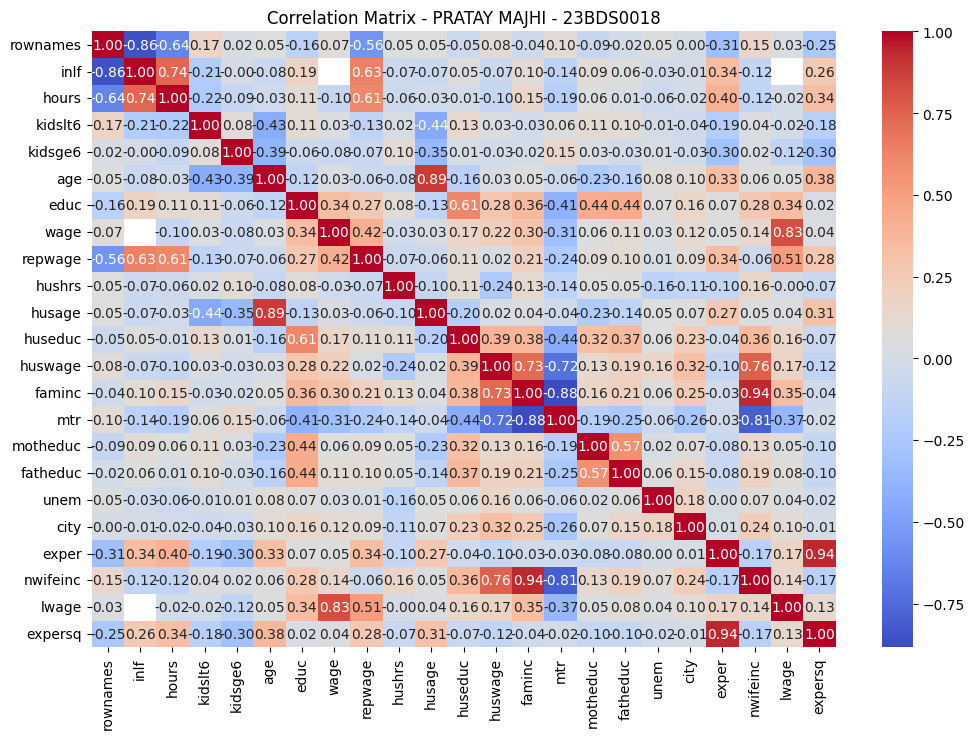

In [50]:
# ============================================================
# SECTION 30: N-DIMENSIONAL ANALYSIS
# ============================================================

# Select numerical columns automatically

numeric_columns_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018
    .select_dtypes(
        include=np.number
    )
)

# Calculate correlation matrix

correlation_23BDS0018 = (
    numeric_columns_23BDS0018
    .corr()
)

print("CORRELATION MATRIX")

print(
    correlation_23BDS0018
)


# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_23BDS0018,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix - PRATAY MAJHI - 23BDS0018"
)

plt.show()

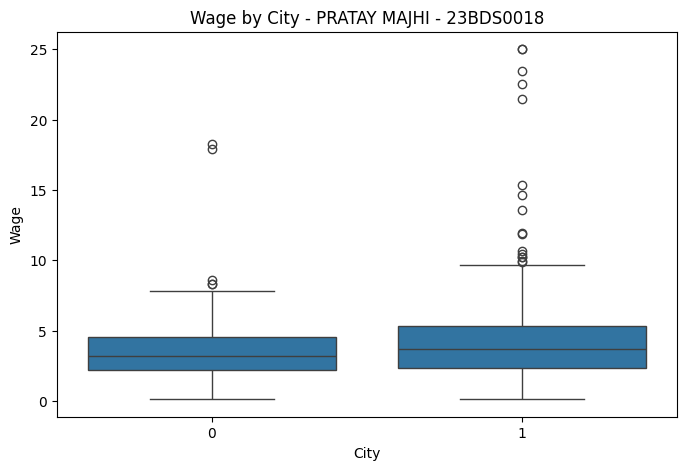

In [48]:
# ============================================================
# SECTION 29: WAGE × CITY
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=PRATAY_MAJHI_23BDS0018,
    x="city",
    y="wage"
)

plt.title(
    "Wage by City - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("City")
plt.ylabel("Wage")

plt.show()

CORRELATION MATRIX
          rownames      inlf     hours   kidslt6   kidsge6       age  \
rownames  1.000000 -0.857886 -0.638588  0.170071  0.016401  0.053285   
inlf     -0.857886  1.000000  0.741145 -0.213749 -0.002424 -0.080498   
hours    -0.638588  0.741145  1.000000 -0.222063 -0.090632 -0.033114   
kidslt6   0.170071 -0.213749 -0.222063  1.000000  0.084160 -0.433949   
kidsge6   0.016401 -0.002424 -0.090632  0.084160  1.000000 -0.385411   
age       0.053285 -0.080498 -0.033114 -0.433949 -0.385411  1.000000   
educ     -0.160816  0.187353  0.105960  0.108690 -0.058899 -0.120223   
wage      0.073182       NaN -0.097628  0.031423 -0.079228  0.030394   
repwage  -0.559615  0.634049  0.606916 -0.134909 -0.068680 -0.058315   
hushrs    0.053309 -0.065183 -0.056348  0.024292  0.099378 -0.084372   
husage    0.052089 -0.072820 -0.031089 -0.442991 -0.350199  0.888138   
huseduc  -0.053115  0.045914 -0.009650  0.133623  0.009437 -0.163049   
huswage   0.085000 -0.069475 -0.098599  0.032

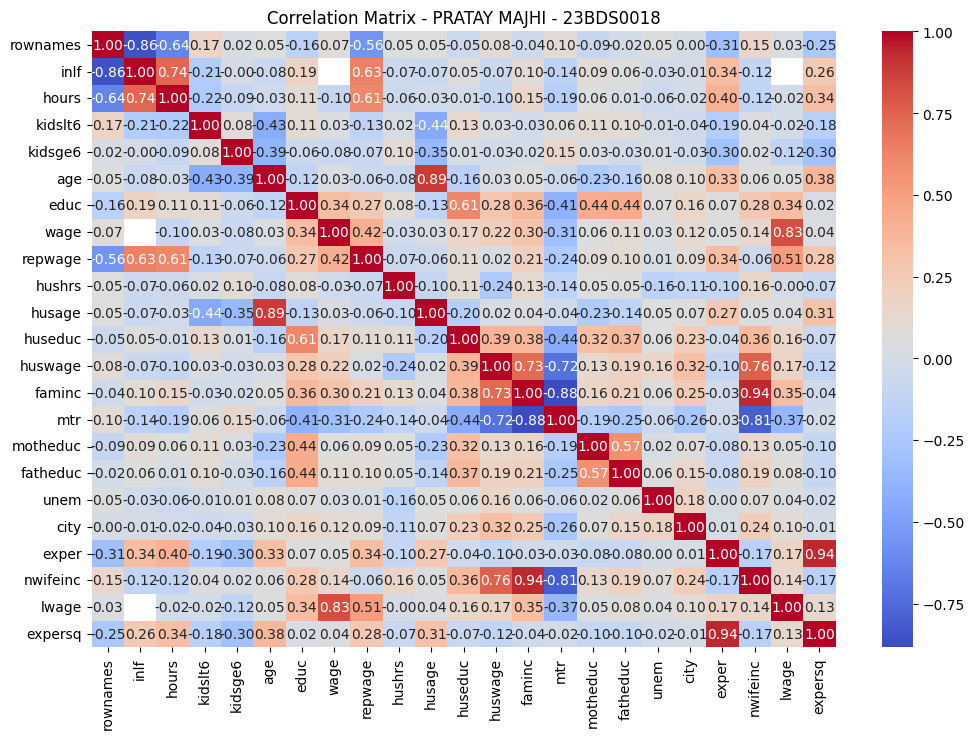

In [49]:
# ============================================================
# SECTION 30: N-DIMENSIONAL ANALYSIS
# ============================================================

# Select numerical columns automatically

numeric_columns_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018
    .select_dtypes(
        include=np.number
    )
)

# Calculate correlation matrix

correlation_23BDS0018 = (
    numeric_columns_23BDS0018
    .corr()
)

print("CORRELATION MATRIX")

print(
    correlation_23BDS0018
)


# ------------------------------------------------------------
# HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_23BDS0018,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title(
    "Correlation Matrix - PRATAY MAJHI - 23BDS0018"
)

plt.show()

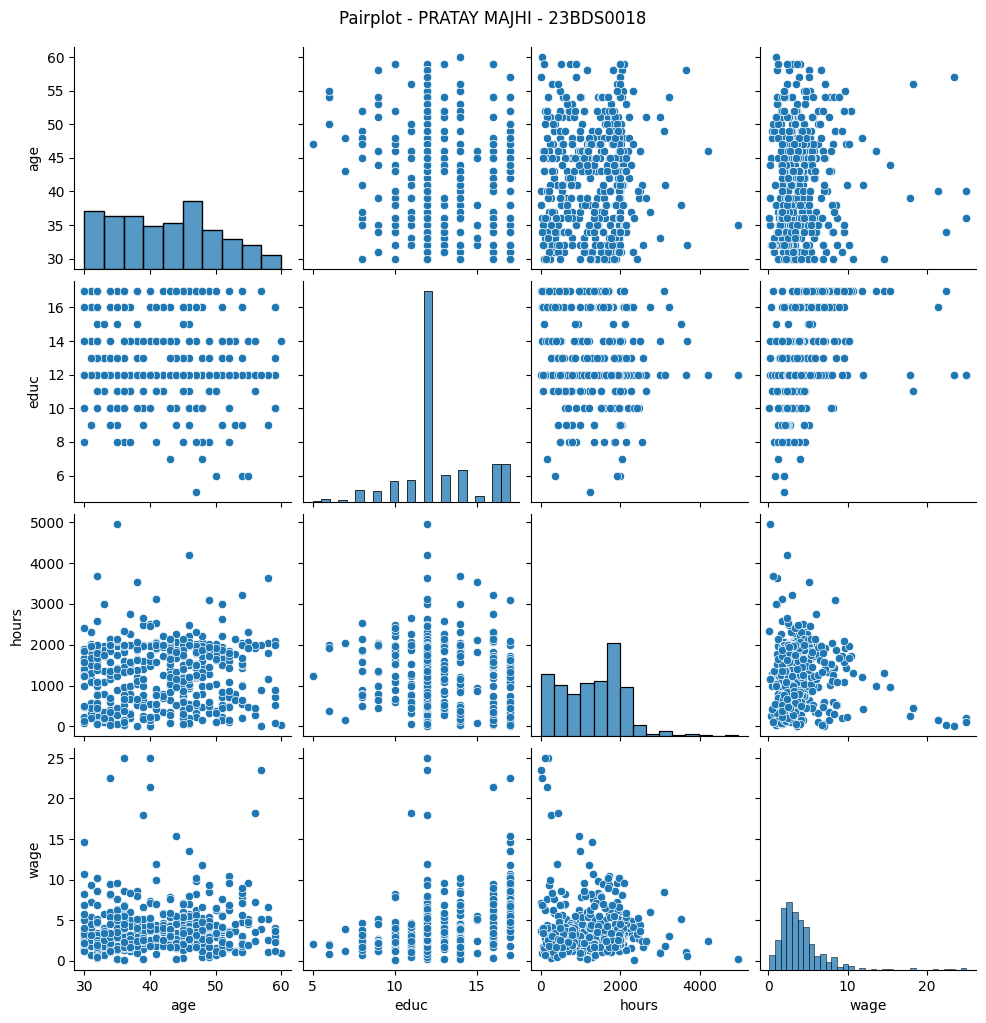

In [51]:
# ============================================================
# SECTION 31: PAIRPLOT
# ============================================================

# Select important numerical variables

pair_columns_23BDS0018 = [
    "age",
    "educ",
    "hours",
    "wage"
]

pair_data_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        pair_columns_23BDS0018
    ]
    .dropna()
)


# Pairplot shows:
# - distribution of every variable
# - relationship between every pair

sns.pairplot(
    pair_data_23BDS0018
)

plt.suptitle(
    "Pairplot - PRATAY MAJHI - 23BDS0018",
    y=1.02
)

plt.show()

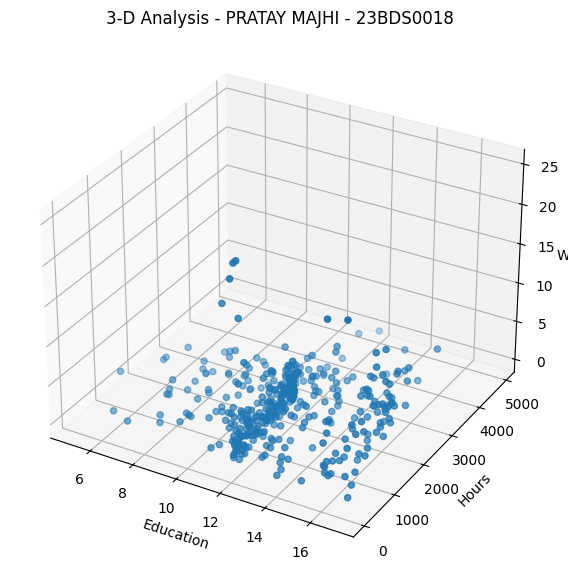

In [53]:
# ============================================================
# SECTION 32: 3-D SCATTER PLOT
# Education × Hours × Wage
# ============================================================

three_d_data_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        ["educ", "hours", "wage"]
    ]
    .dropna()
)


# Create 3-D figure

fig = plt.figure(
    figsize=(10, 7)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Plot the three variables

ax.scatter(
    three_d_data_23BDS0018["educ"],
    three_d_data_23BDS0018["hours"],
    three_d_data_23BDS0018["wage"]
)


# Axis labels

ax.set_xlabel("Education")
ax.set_ylabel("Hours")
ax.set_zlabel("Wage")


ax.set_title(
    "3-D Analysis - PRATAY MAJHI - 23BDS0018"
)

plt.show()

In [54]:
# ============================================================
# SECTION 33: CLUSTERING DATA PREPARATION
# ============================================================

# Variables selected for clustering

cluster_columns_23BDS0018 = [
    "age",
    "educ",
    "hours",
    "wage",
    "faminc",
    "exper"
]


# Remove rows having missing values in these variables

cluster_data_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        cluster_columns_23BDS0018
    ]
    .dropna()
)


# ------------------------------------------------------------
# STANDARDIZATION
# ------------------------------------------------------------

# Clustering is distance-based.
# Variables with large numerical scales can dominate the distance.
#
# StandardScaler converts variables approximately to:
# mean = 0
# standard deviation = 1

scaler_23BDS0018 = StandardScaler()

cluster_scaled_23BDS0018 = (
    scaler_23BDS0018
    .fit_transform(
        cluster_data_23BDS0018
    )
)


print(
    "STANDARDIZED DATA"
)

print(
    cluster_scaled_23BDS0018[:5]
)

STANDARDIZED DATA
[[-1.2930351  -0.28863945  0.39603194 -0.24911633 -0.67084253  0.11963165]
 [-1.55236923 -0.28863945  0.45535868 -0.84344622 -0.19990566 -0.99886618]
 [-0.90403391 -0.28863945  0.87322533  0.1112439  -0.26509911  0.24390918]
 [-1.03370098 -0.28863945 -1.09229554 -0.93188042 -1.44372801 -0.87458865]
 [-1.42270217  0.58751433  0.34186404  0.12524711  0.27188902 -0.75031111]]


In [55]:
# ============================================================
# SECTION 33: CLUSTERING DATA PREPARATION
# ============================================================

# Variables selected for clustering

cluster_columns_23BDS0018 = [
    "age",
    "educ",
    "hours",
    "wage",
    "faminc",
    "exper"
]


# Remove rows having missing values in these variables

cluster_data_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        cluster_columns_23BDS0018
    ]
    .dropna()
)


# ------------------------------------------------------------
# STANDARDIZATION
# ------------------------------------------------------------

# Clustering is distance-based.
# Variables with large numerical scales can dominate the distance.
#
# StandardScaler converts variables approximately to:
# mean = 0
# standard deviation = 1

scaler_23BDS0018 = StandardScaler()

cluster_scaled_23BDS0018 = (
    scaler_23BDS0018
    .fit_transform(
        cluster_data_23BDS0018
    )
)


print(
    "STANDARDIZED DATA"
)

print(
    cluster_scaled_23BDS0018[:5]
)

STANDARDIZED DATA
[[-1.2930351  -0.28863945  0.39603194 -0.24911633 -0.67084253  0.11963165]
 [-1.55236923 -0.28863945  0.45535868 -0.84344622 -0.19990566 -0.99886618]
 [-0.90403391 -0.28863945  0.87322533  0.1112439  -0.26509911  0.24390918]
 [-1.03370098 -0.28863945 -1.09229554 -0.93188042 -1.44372801 -0.87458865]
 [-1.42270217  0.58751433  0.34186404  0.12524711  0.27188902 -0.75031111]]


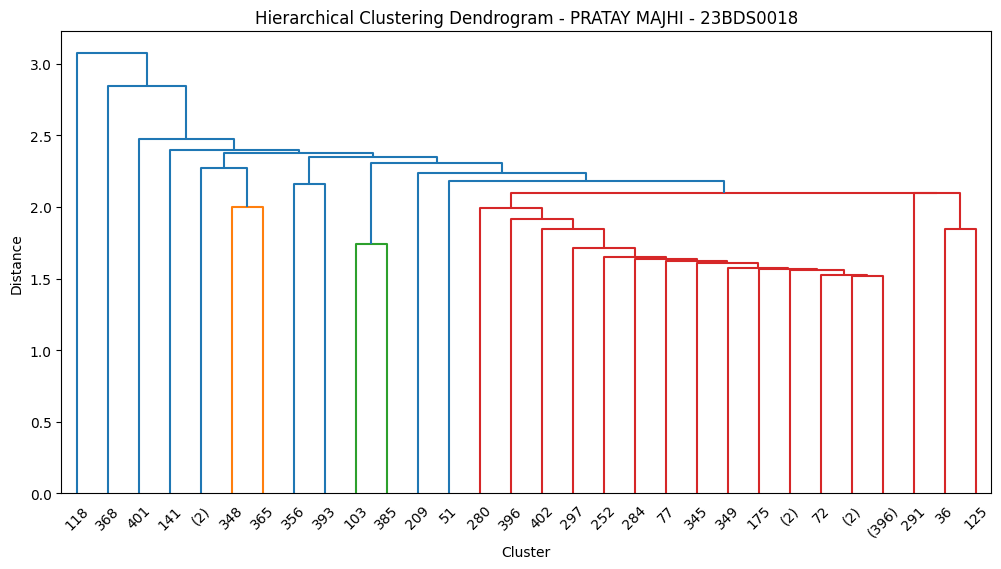

In [56]:
# ============================================================
# SECTION 34: HIERARCHICAL CLUSTERING
# ============================================================

# linkage() builds the hierarchical clustering structure.

hierarchical_23BDS0018 = linkage(
    cluster_scaled_23BDS0018,
    method="single"
)


# ------------------------------------------------------------
# DENDROGRAM
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

dendrogram(
    hierarchical_23BDS0018,
    truncate_mode="lastp",
    p=30
)

plt.title(
    "Hierarchical Clustering Dendrogram - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Cluster")
plt.ylabel("Distance")

plt.show()

In [57]:
# ============================================================
# SECTION 35: HIERARCHICAL CLUSTER LABELS
# ============================================================

# Divide observations into 3 clusters

hierarchical_labels_23BDS0018 = fcluster(
    hierarchical_23BDS0018,
    t=3,
    criterion="maxclust"
)


print("FIRST 20 HIERARCHICAL CLUSTER LABELS")

print(
    hierarchical_labels_23BDS0018[:20]
)

FIRST 20 HIERARCHICAL CLUSTER LABELS
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


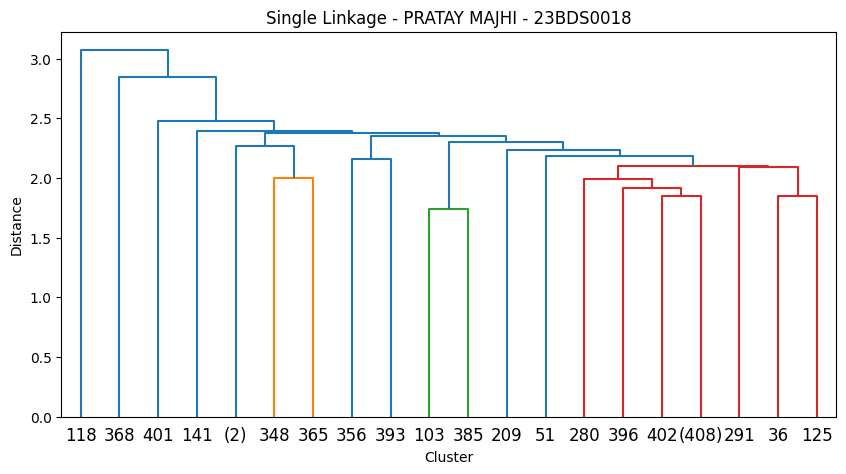

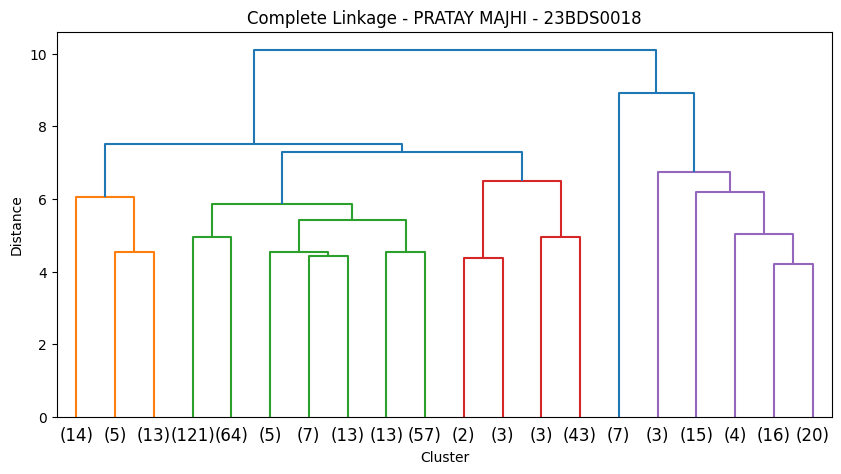

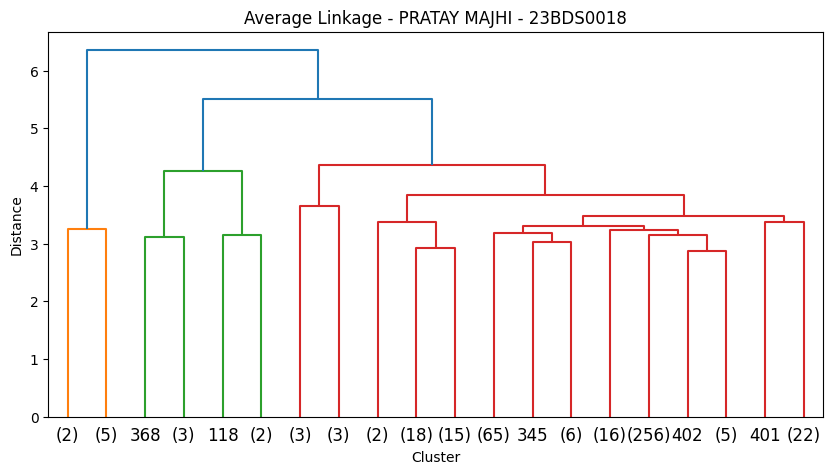

In [58]:
# ============================================================
# SECTION 36: LINKAGE COMPARISON
# ============================================================

# We compare:
# 1. Single linkage
# 2. Complete linkage
# 3. Average linkage

linkage_methods_23BDS0018 = [
    "single",
    "complete",
    "average"
]


for method_23BDS0018 in linkage_methods_23BDS0018:

    # Perform hierarchical clustering
    linkage_result_23BDS0018 = linkage(
        cluster_scaled_23BDS0018,
        method=method_23BDS0018
    )

    # Draw dendrogram
    plt.figure(figsize=(10, 5))

    dendrogram(
        linkage_result_23BDS0018,
        truncate_mode="lastp",
        p=20
    )

    plt.title(
        method_23BDS0018.title()
        +
        " Linkage - PRATAY MAJHI - 23BDS0018"
    )

    plt.xlabel("Cluster")
    plt.ylabel("Distance")

    plt.show()

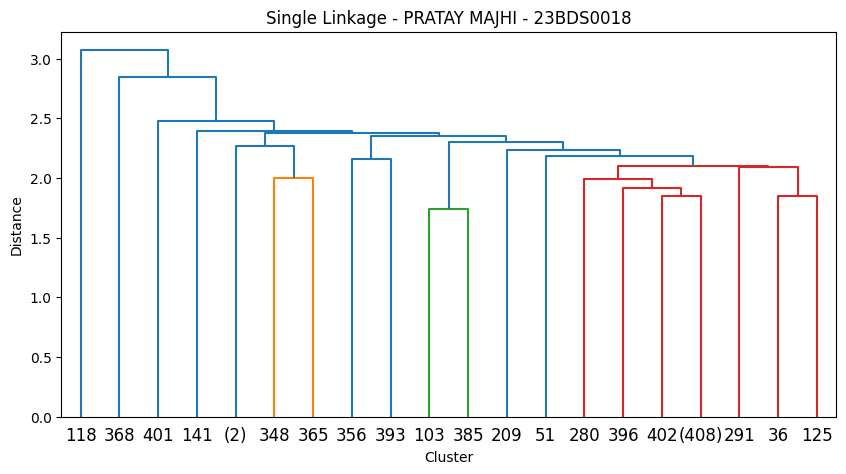

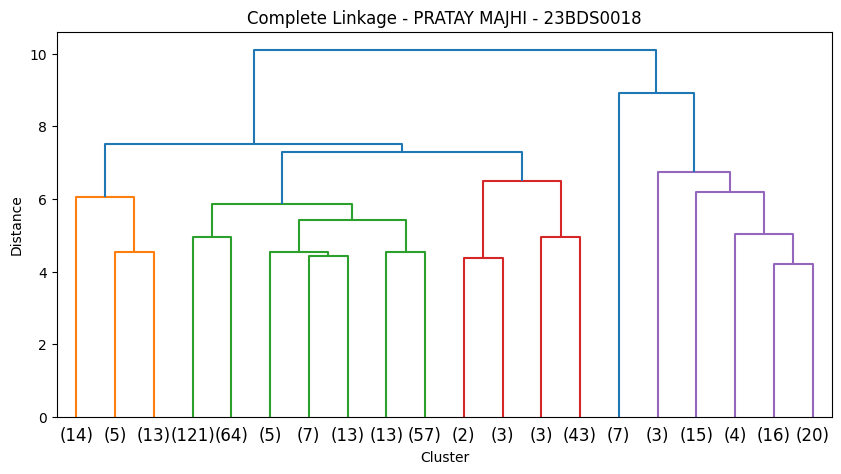

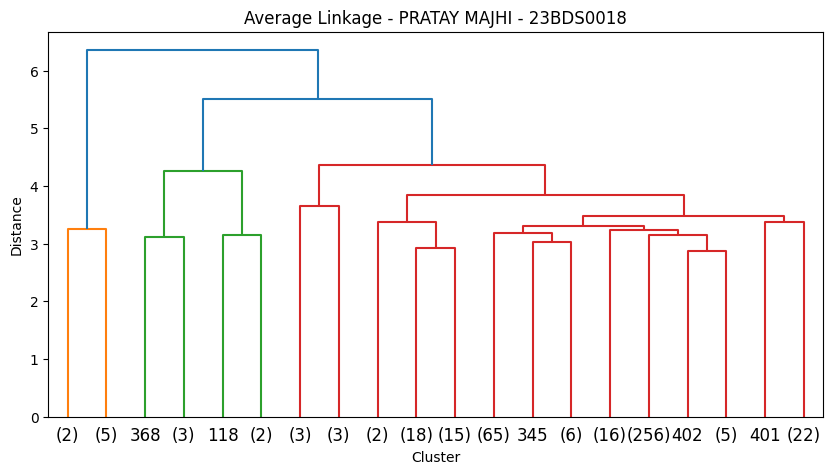

In [59]:
# ============================================================
# SECTION 36: LINKAGE COMPARISON
# ============================================================

# We compare:
# 1. Single linkage
# 2. Complete linkage
# 3. Average linkage

linkage_methods_23BDS0018 = [
    "single",
    "complete",
    "average"
]


for method_23BDS0018 in linkage_methods_23BDS0018:

    # Perform hierarchical clustering
    linkage_result_23BDS0018 = linkage(
        cluster_scaled_23BDS0018,
        method=method_23BDS0018
    )

    # Draw dendrogram
    plt.figure(figsize=(10, 5))

    dendrogram(
        linkage_result_23BDS0018,
        truncate_mode="lastp",
        p=20
    )

    plt.title(
        method_23BDS0018.title()
        +
        " Linkage - PRATAY MAJHI - 23BDS0018"
    )

    plt.xlabel("Cluster")
    plt.ylabel("Distance")

    plt.show()

FIRST 20 K-MEANS CLUSTER LABELS
[2 2 2 2 2 0 1 0 0 0 2 0 2 2 2 2 0 2 0 2]


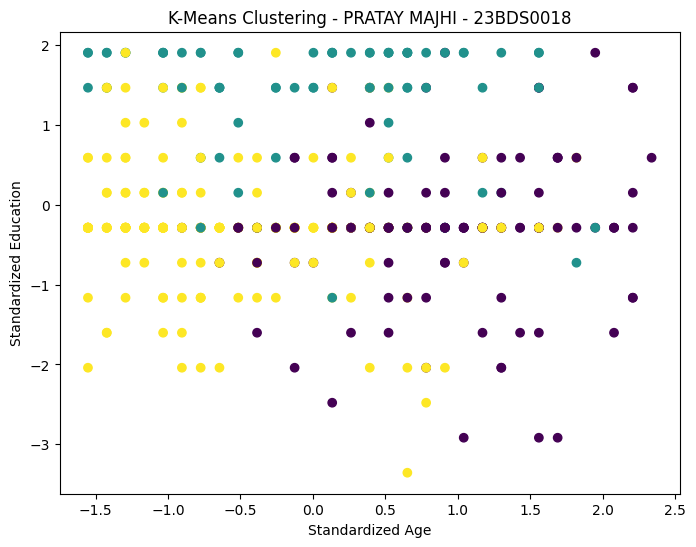

In [60]:
# ============================================================
# SECTION 37: K-MEANS CLUSTERING
# ============================================================

# Create K-Means model with 3 clusters

kmeans_23BDS0018 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)


# Train model and obtain cluster labels

kmeans_labels_23BDS0018 = (
    kmeans_23BDS0018
    .fit_predict(
        cluster_scaled_23BDS0018
    )
)


print("FIRST 20 K-MEANS CLUSTER LABELS")

print(
    kmeans_labels_23BDS0018[:20]
)


# ------------------------------------------------------------
# VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=kmeans_labels_23BDS0018
)

plt.title(
    "K-Means Clustering - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()

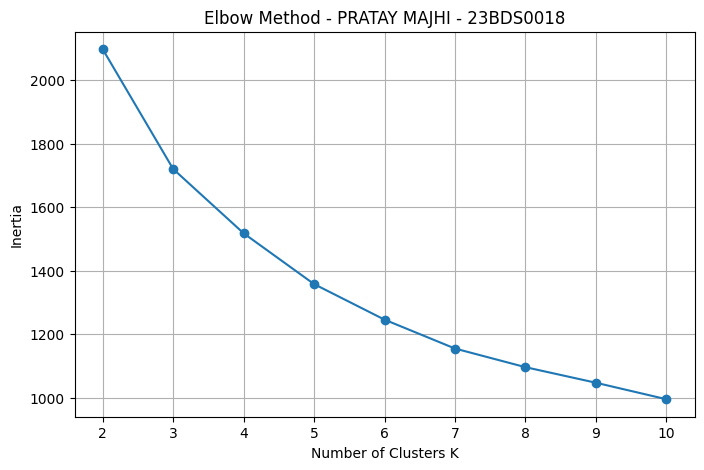

In [63]:
# ============================================================
# SECTION 38: ELBOW METHOD
# ============================================================

# Store the within-cluster sum of squares
# for different values of K.

inertia_23BDS0018 = []

K_values_23BDS0018 = range(2, 11)


for k_23BDS0018 in K_values_23BDS0018:

    model_23BDS0018 = KMeans(
        n_clusters=k_23BDS0018,
        random_state=42,
        n_init=10
    )

    model_23BDS0018.fit(
        cluster_scaled_23BDS0018
    )

    inertia_23BDS0018.append(
        model_23BDS0018.inertia_
    )


# ------------------------------------------------------------
# ELBOW PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    K_values_23BDS0018,
    inertia_23BDS0018,
    marker="o"
)

plt.title(
    "Elbow Method - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Number of Clusters K")
plt.ylabel("Inertia")

plt.grid()

plt.show()

In [62]:
# ============================================================
# SECTION 39: SILHOUETTE SCORE
# ============================================================

# Silhouette score measures how well observations
# fit within their assigned clusters.

silhouette_23BDS0018 = silhouette_score(
    cluster_scaled_23BDS0018,
    kmeans_labels_23BDS0018
)


print(
    "SILHOUETTE SCORE"
)

print(
    silhouette_23BDS0018
)

SILHOUETTE SCORE
0.21080294288947196


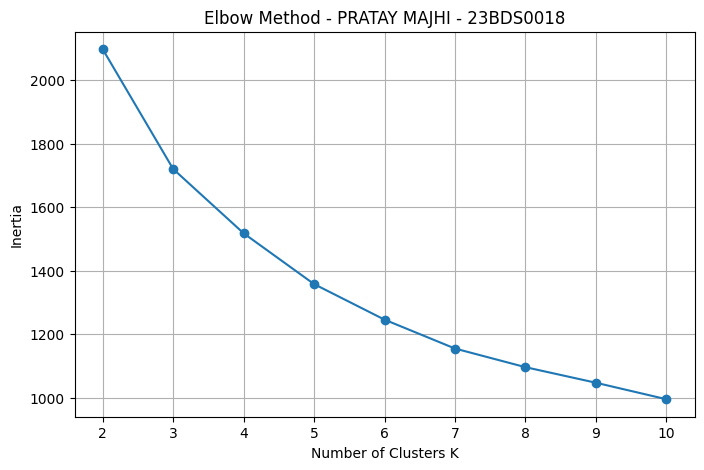

In [64]:
# ============================================================
# SECTION 38: ELBOW METHOD
# ============================================================

# Store the within-cluster sum of squares
# for different values of K.

inertia_23BDS0018 = []

K_values_23BDS0018 = range(2, 11)


for k_23BDS0018 in K_values_23BDS0018:

    model_23BDS0018 = KMeans(
        n_clusters=k_23BDS0018,
        random_state=42,
        n_init=10
    )

    model_23BDS0018.fit(
        cluster_scaled_23BDS0018
    )

    inertia_23BDS0018.append(
        model_23BDS0018.inertia_
    )


# ------------------------------------------------------------
# ELBOW PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    K_values_23BDS0018,
    inertia_23BDS0018,
    marker="o"
)

plt.title(
    "Elbow Method - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Number of Clusters K")
plt.ylabel("Inertia")

plt.grid()

plt.show()

FIRST 30 DBSCAN LABELS
[ 0  0  0  0 -1  0 -1 -1  0  0  0  0  1  0 -1  0  0  0  0 -1 -1  0  0  0
  0 -1 -1  0 -1  0]


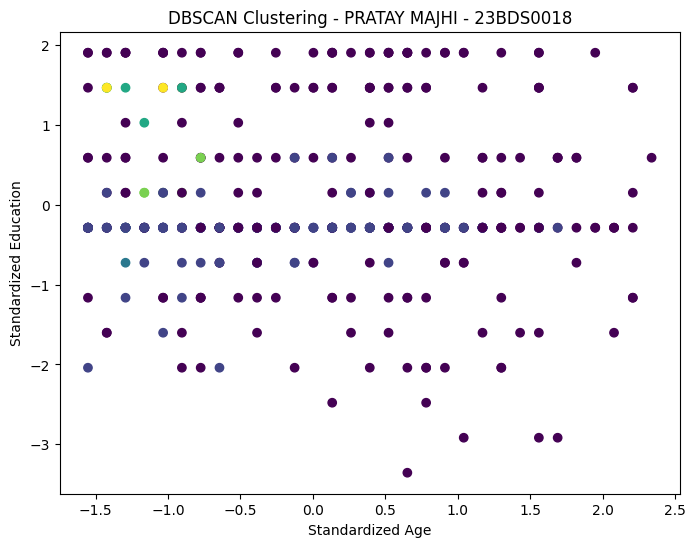

In [65]:
# ============================================================
# SECTION 40: DBSCAN
# ============================================================

# eps defines the neighborhood radius.
# min_samples defines the minimum number of points
# required to form a dense region.

dbscan_23BDS0018 = DBSCAN(
    eps=0.8,
    min_samples=4
)


# Generate cluster labels

dbscan_labels_23BDS0018 = (
    dbscan_23BDS0018
    .fit_predict(
        cluster_scaled_23BDS0018
    )
)


print("FIRST 30 DBSCAN LABELS")

print(
    dbscan_labels_23BDS0018[:30]
)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=dbscan_labels_23BDS0018
)

plt.title(
    "DBSCAN Clustering - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()

NUMBER OF DBSCAN OUTLIERS
236


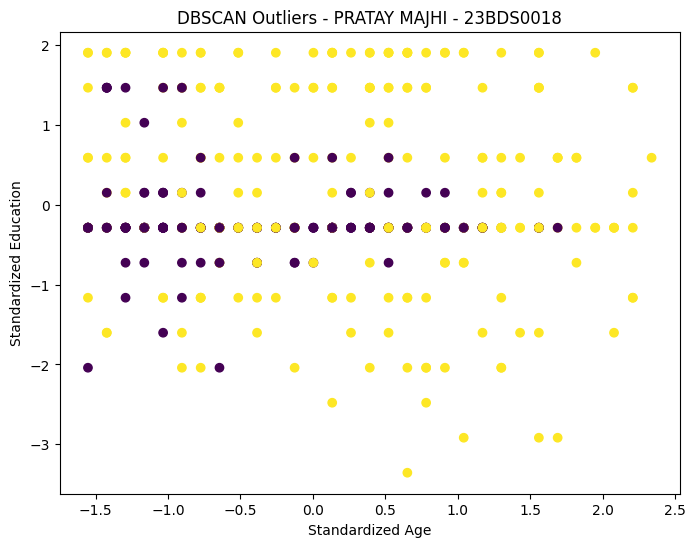

In [67]:
# ============================================================
# SECTION 41: DBSCAN OUTLIERS
# ============================================================

# DBSCAN uses -1 to represent noise/outliers.

dbscan_outliers_23BDS0018 = (
    dbscan_labels_23BDS0018 == -1
)


print(
    "NUMBER OF DBSCAN OUTLIERS"
)

print(
    dbscan_outliers_23BDS0018.sum()
)


# ------------------------------------------------------------
# PLOT OUTLIERS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=dbscan_outliers_23BDS0018
)

plt.title(
    "DBSCAN Outliers - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()

In [66]:
# ============================================================
# SECTION 42: EM / GAUSSIAN MIXTURE MODEL
# ============================================================

# Create Gaussian Mixture Model
# with 3 Gaussian components.

em_23BDS0018 = GaussianMixture(
    n_components=3,
    random_state=42
)


# Fit the model

em_23BDS0018.fit(
    cluster_scaled_23BDS0018
)


# Predict cluster/component labels

em_labels_23BDS0018 = (
    em_23BDS0018
    .predict(
        cluster_scaled_23BDS0018
    )
)


print(
    "FIRST 20 EM CLUSTER LABELS"
)

print(
    em_labels_23BDS0018[:20]
)

FIRST 20 EM CLUSTER LABELS
[1 1 1 1 0 1 2 1 1 1 1 0 1 1 0 0 1 1 1 1]


NUMBER OF DBSCAN OUTLIERS
236


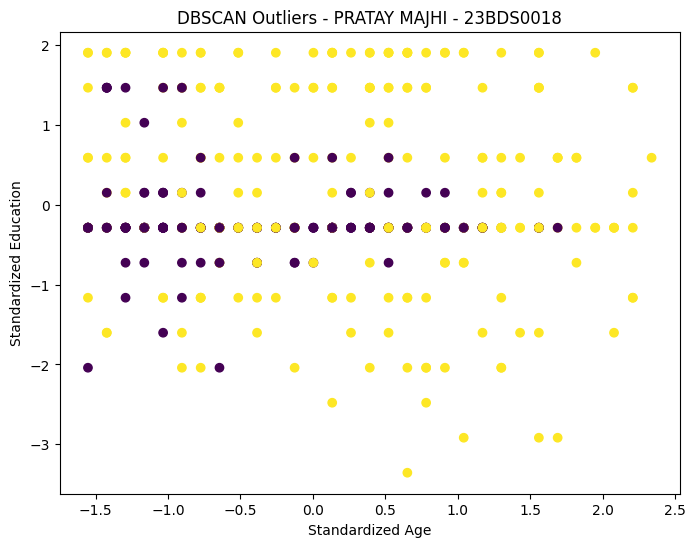

In [68]:
# ============================================================
# SECTION 41: DBSCAN OUTLIERS
# ============================================================

# DBSCAN uses -1 to represent noise/outliers.

dbscan_outliers_23BDS0018 = (
    dbscan_labels_23BDS0018 == -1
)


print(
    "NUMBER OF DBSCAN OUTLIERS"
)

print(
    dbscan_outliers_23BDS0018.sum()
)


# ------------------------------------------------------------
# PLOT OUTLIERS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=dbscan_outliers_23BDS0018
)

plt.title(
    "DBSCAN Outliers - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()

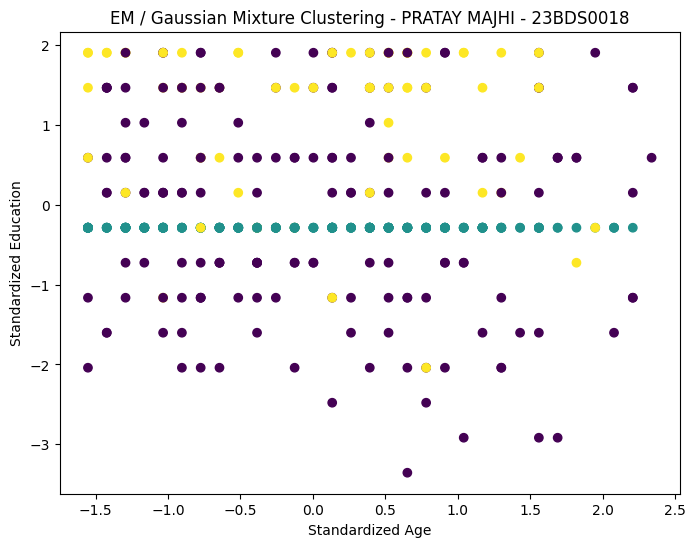

GAUSSIAN MEANS
[[ 0.05470183 -0.09205491  0.15383814 -0.22861838 -0.19437467  0.09773889]
 [-0.0377665  -0.28863945  0.0278541  -0.24576361 -0.17970526  0.03606953]
 [-0.00960575  1.08397596 -0.43348261  1.26382092  0.98584702 -0.33111119]]

GAUSSIAN COVARIANCES
[[[ 1.08890320e+00 -9.82198860e-02 -2.08968882e-02  2.35378811e-02
    9.18589739e-03  6.99224782e-01]
  [-9.82198860e-02  1.75215972e+00 -2.16823446e-02  3.40152613e-01
    3.72824176e-01  9.70541641e-02]
  [-2.08968882e-02 -2.16823446e-02  1.01874969e+00  1.20352200e-01
    1.83723931e-01  2.04649305e-01]
  [ 2.35378811e-02  3.40152613e-01  1.20352200e-01  3.17886929e-01
    2.41350573e-01  2.07335401e-01]
  [ 9.18589739e-03  3.72824176e-01  1.83723931e-01  2.41350573e-01
    5.26703316e-01  3.73597278e-02]
  [ 6.99224782e-01  9.70541641e-02  2.04649305e-01  2.07335401e-01
    3.73597278e-02  1.27734671e+00]]

 [[ 9.51116550e-01 -9.57578452e-34  8.36300633e-02  8.97031839e-02
    1.42656952e-01  4.30954174e-01]
  [-1.43636768

In [69]:
# ============================================================
# SECTION 43: EM VISUALIZATION
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=em_labels_23BDS0018
)

plt.title(
    "EM / Gaussian Mixture Clustering - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()


# ------------------------------------------------------------
# MODEL PARAMETERS
# ------------------------------------------------------------

print("GAUSSIAN MEANS")

print(
    em_23BDS0018.means_
)


print("\nGAUSSIAN COVARIANCES")

print(
    em_23BDS0018.covariances_
)


# AIC measures model fit while penalizing complexity
print("\nAIC")

print(
    em_23BDS0018.aic(
        cluster_scaled_23BDS0018
    )
)


# BIC also evaluates model fit with a complexity penalty
print("\nBIC")

print(
    em_23BDS0018.bic(
        cluster_scaled_23BDS0018
    )
)

FIRST 20 SPECTRAL CLUSTER LABELS
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


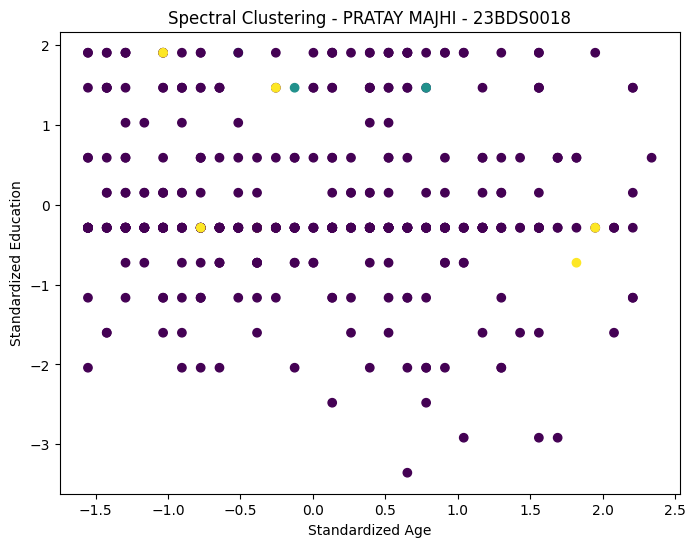

In [70]:
# ============================================================
# SECTION 44: SPECTRAL CLUSTERING
# ============================================================

# Spectral clustering uses relationships between observations.
#
# RBF is used as the affinity function.

spectral_23BDS0018 = SpectralClustering(
    n_clusters=3,
    affinity="rbf",
    random_state=42
)


# Calculate cluster labels

spectral_labels_23BDS0018 = (
    spectral_23BDS0018
    .fit_predict(
        cluster_scaled_23BDS0018
    )
)


print(
    "FIRST 20 SPECTRAL CLUSTER LABELS"
)

print(
    spectral_labels_23BDS0018[:20]
)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    cluster_scaled_23BDS0018[:, 0],
    cluster_scaled_23BDS0018[:, 1],
    c=spectral_labels_23BDS0018
)

plt.title(
    "Spectral Clustering - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Standardized Age")
plt.ylabel("Standardized Education")

plt.show()

Number of observations used for MST: 100

DISTANCE MATRIX SHAPE:
(100, 100)

MST MATRIX SHAPE:
(100, 100)

NUMBER OF MST EDGES:
99

TOTAL MST DISTANCE:
113.10184179208954


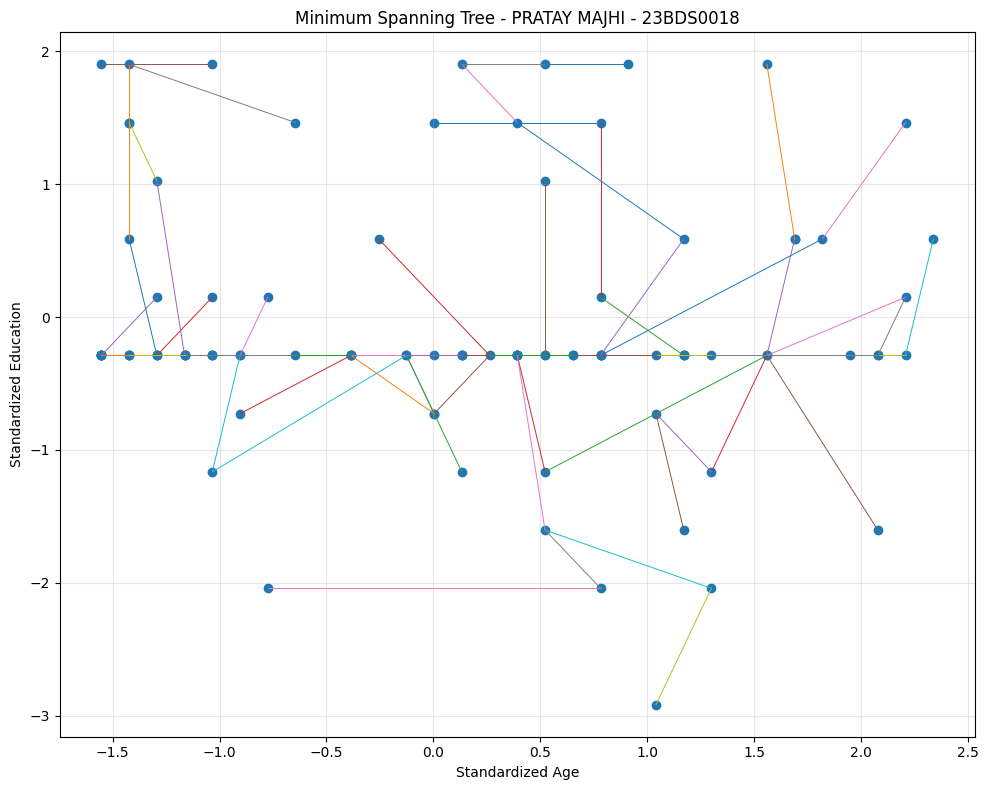

In [73]:
# ============================================================
# SECTION 45: MINIMUM SPANNING TREE (MST)
# Name   : PRATAY MAJHI
# Reg No : 23BDS0018
# ============================================================

# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

# pandas is used for data handling
import pandas as pd

# numpy is used for numerical operations
import numpy as np

# matplotlib is used for plotting
import matplotlib.pyplot as plt

# StandardScaler is used to standardize the variables
from sklearn.preprocessing import StandardScaler

# pairwise_distances calculates the distance between
# every pair of observations
from sklearn.metrics import pairwise_distances

# minimum_spanning_tree calculates the MST
from scipy.sparse.csgraph import minimum_spanning_tree


# ------------------------------------------------------------
# LOAD THE MROZ DATASET
# ------------------------------------------------------------

PRATAY_MAJHI_23BDS0018 = pd.read_csv(
    "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/mroz.csv"
)


# ------------------------------------------------------------
# SELECT VARIABLES FOR MST
# ------------------------------------------------------------

# We select numerical variables that describe the observations.

mst_columns_23BDS0018 = [
    "age",
    "educ",
    "hours",
    "wage",
    "faminc",
    "exper"
]


# Remove rows containing missing values
mst_data_raw_23BDS0018 = (
    PRATAY_MAJHI_23BDS0018[
        mst_columns_23BDS0018
    ]
    .dropna()
)


# ------------------------------------------------------------
# STANDARDIZE THE DATA
# ------------------------------------------------------------

# Standardization is important because variables such as
# wage, age, education and hours have different scales.

scaler_23BDS0018 = StandardScaler()

cluster_scaled_23BDS0018 = (
    scaler_23BDS0018.fit_transform(
        mst_data_raw_23BDS0018
    )
)


# ------------------------------------------------------------
# SELECT FIRST 100 OBSERVATIONS
# ------------------------------------------------------------

# Using all observations can make the MST graph crowded.
# Therefore, we use the first 100 observations.

mst_data_23BDS0018 = (
    cluster_scaled_23BDS0018[:100]
)


print(
    "Number of observations used for MST:",
    len(mst_data_23BDS0018)
)


# ------------------------------------------------------------
# CALCULATE PAIRWISE DISTANCES
# ------------------------------------------------------------

# pairwise_distances calculates the Euclidean distance
# between every pair of observations.
#
# Example:
#
# Observation 1 <----distance----> Observation 2
#
# The result is a distance matrix.

distance_matrix_23BDS0018 = pairwise_distances(
    mst_data_23BDS0018,
    metric="euclidean"
)


print(
    "\nDISTANCE MATRIX SHAPE:"
)

print(
    distance_matrix_23BDS0018.shape
)


# ------------------------------------------------------------
# CALCULATE MINIMUM SPANNING TREE
# ------------------------------------------------------------

# minimum_spanning_tree finds a set of edges that:
#
# 1. Connects all observations
# 2. Contains no unnecessary cycles
# 3. Has minimum possible total distance

mst_23BDS0018 = minimum_spanning_tree(
    distance_matrix_23BDS0018
)


# Convert the sparse matrix into a normal NumPy array

mst_array_23BDS0018 = (
    mst_23BDS0018.toarray()
)


print(
    "\nMST MATRIX SHAPE:"
)

print(
    mst_array_23BDS0018.shape
)


# ------------------------------------------------------------
# COUNT MST EDGES
# ------------------------------------------------------------

# Every MST containing n observations should have n-1 edges.

number_of_edges_23BDS0018 = np.count_nonzero(
    mst_array_23BDS0018
)

print(
    "\nNUMBER OF MST EDGES:"
)

print(
    number_of_edges_23BDS0018
)


# ------------------------------------------------------------
# TOTAL MST DISTANCE
# ------------------------------------------------------------

# Sum of all edge weights gives the total length
# of the Minimum Spanning Tree.

total_mst_distance_23BDS0018 = (
    mst_array_23BDS0018.sum()
)

print(
    "\nTOTAL MST DISTANCE:"
)

print(
    total_mst_distance_23BDS0018
)


# ============================================================
# MST VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 8))


# ------------------------------------------------------------
# PLOT OBSERVATIONS
# ------------------------------------------------------------

# We use:
# X-axis = Standardized Age
# Y-axis = Standardized Education

plt.scatter(
    mst_data_23BDS0018[:, 0],
    mst_data_23BDS0018[:, 1]
)


# ------------------------------------------------------------
# DRAW MST EDGES
# ------------------------------------------------------------

# The MST matrix contains the connection between
# observation i and observation j.
#
# If the value is greater than zero,
# an MST edge exists between those two observations.

for i_23BDS0018 in range(
    len(mst_array_23BDS0018)
):

    for j_23BDS0018 in range(
        len(mst_array_23BDS0018)
    ):

        if (
            mst_array_23BDS0018[
                i_23BDS0018,
                j_23BDS0018
            ] > 0
        ):

            plt.plot(
                [
                    mst_data_23BDS0018[
                        i_23BDS0018, 0
                    ],
                    mst_data_23BDS0018[
                        j_23BDS0018, 0
                    ]
                ],
                [
                    mst_data_23BDS0018[
                        i_23BDS0018, 1
                    ],
                    mst_data_23BDS0018[
                        j_23BDS0018, 1
                    ]
                ],
                linewidth=0.7
            )


# ------------------------------------------------------------
# LABEL THE GRAPH
# ------------------------------------------------------------

plt.title(
    "Minimum Spanning Tree - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel(
    "Standardized Age"
)

plt.ylabel(
    "Standardized Education"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

DOCUMENT-TERM MATRIX
      brown  chased  dog  fox  is  jumps  lazy  over  quick  the
Doc1      1       0    1    1   0      1     1     1      1    2
Doc2      1       1    1    1   0      0     0     0      0    1
Doc3      0       0    1    0   1      0     1     0      0    1


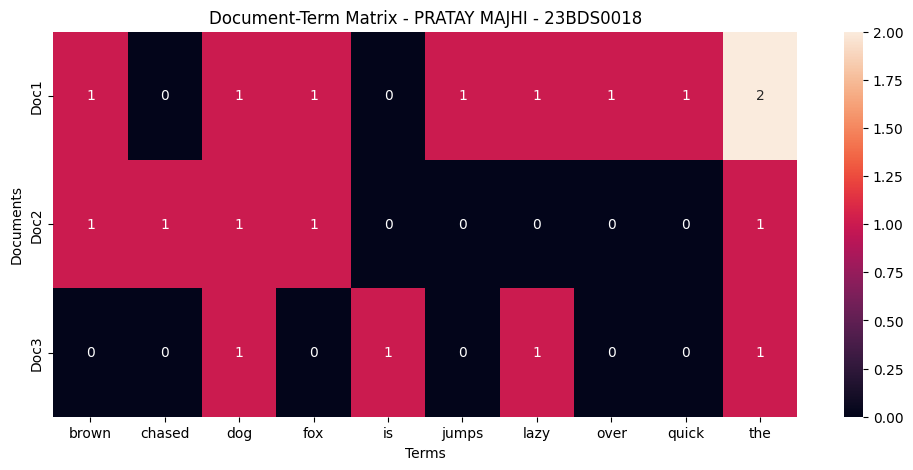

In [75]:
# ============================================================
# SECTION 46: DOCUMENT CLUSTERING
# Based on the Module 5 document example
# ============================================================


# ------------------------------------------------------------
# DOCUMENTS
# ------------------------------------------------------------

documents_23BDS0018 = [
    "the quick brown fox jumps over the lazy dog",
    "a brown dog chased the fox",
    "the dog is lazy"
]


# ------------------------------------------------------------
# CREATE DOCUMENT-TERM MATRIX
# ------------------------------------------------------------

# CountVectorizer converts text into numerical vectors.
#
# Each column represents a word.
# Each row represents a document.

vectorizer_23BDS0018 = CountVectorizer()

document_matrix_23BDS0018 = (
    vectorizer_23BDS0018
    .fit_transform(
        documents_23BDS0018
    )
)


# Convert matrix into DataFrame

document_dataframe_23BDS0018 = pd.DataFrame(
    document_matrix_23BDS0018.toarray(),
    columns=vectorizer_23BDS0018.get_feature_names_out(),
    index=[
        "Doc1",
        "Doc2",
        "Doc3"
    ]
)


print("DOCUMENT-TERM MATRIX")

print(
    document_dataframe_23BDS0018
)


# ------------------------------------------------------------
# DOCUMENT-TERM HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

sns.heatmap(
    document_dataframe_23BDS0018,
    annot=True,
    fmt="d"
)

plt.title(
    "Document-Term Matrix - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Terms")
plt.ylabel("Documents")

plt.show()

DOCUMENT-TERM MATRIX
      brown  chased  dog  fox  is  jumps  lazy  over  quick  the
Doc1      1       0    1    1   0      1     1     1      1    2
Doc2      1       1    1    1   0      0     0     0      0    1
Doc3      0       0    1    0   1      0     1     0      0    1


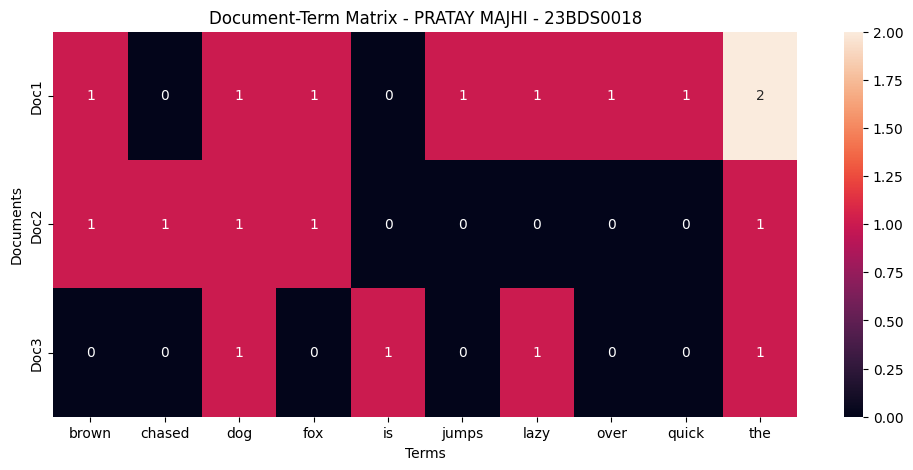

In [76]:
# ============================================================
# SECTION 46: DOCUMENT CLUSTERING
# Based on the Module 5 document example
# ============================================================


# ------------------------------------------------------------
# DOCUMENTS
# ------------------------------------------------------------

documents_23BDS0018 = [
    "the quick brown fox jumps over the lazy dog",
    "a brown dog chased the fox",
    "the dog is lazy"
]


# ------------------------------------------------------------
# CREATE DOCUMENT-TERM MATRIX
# ------------------------------------------------------------

# CountVectorizer converts text into numerical vectors.
#
# Each column represents a word.
# Each row represents a document.

vectorizer_23BDS0018 = CountVectorizer()

document_matrix_23BDS0018 = (
    vectorizer_23BDS0018
    .fit_transform(
        documents_23BDS0018
    )
)


# Convert matrix into DataFrame

document_dataframe_23BDS0018 = pd.DataFrame(
    document_matrix_23BDS0018.toarray(),
    columns=vectorizer_23BDS0018.get_feature_names_out(),
    index=[
        "Doc1",
        "Doc2",
        "Doc3"
    ]
)


print("DOCUMENT-TERM MATRIX")

print(
    document_dataframe_23BDS0018
)


# ------------------------------------------------------------
# DOCUMENT-TERM HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

sns.heatmap(
    document_dataframe_23BDS0018,
    annot=True,
    fmt="d"
)

plt.title(
    "Document-Term Matrix - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Terms")
plt.ylabel("Documents")

plt.show()

COSINE SIMILARITY
Doc1    0.426401
Doc2    0.632456
Doc3    0.353553
dtype: float64


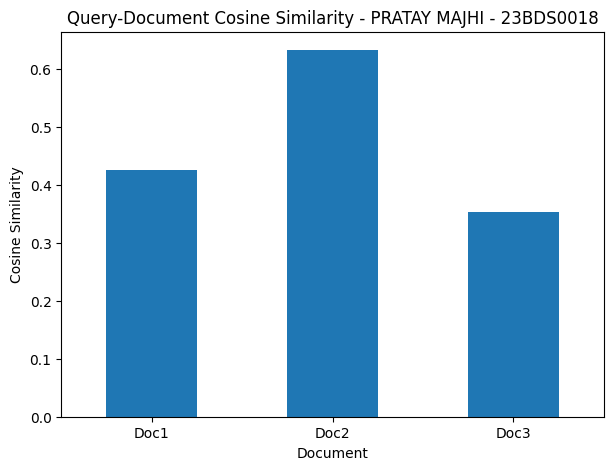

In [77]:
# ============================================================
# SECTION 47: COSINE SIMILARITY
# ============================================================

# Query from the Module 5 example

query_23BDS0018 = [
    "brown dog"
]


# Convert query into the SAME vocabulary
# used for the documents.

query_vector_23BDS0018 = (
    vectorizer_23BDS0018
    .transform(
        query_23BDS0018
    )
)


# Calculate cosine similarity
# between query and every document.

similarity_23BDS0018 = cosine_similarity(
    query_vector_23BDS0018,
    document_matrix_23BDS0018
)


# Convert result into Series

similarity_series_23BDS0018 = pd.Series(
    similarity_23BDS0018[0],
    index=[
        "Doc1",
        "Doc2",
        "Doc3"
    ]
)


print("COSINE SIMILARITY")

print(
    similarity_series_23BDS0018
)


# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

similarity_series_23BDS0018.plot(
    kind="bar"
)

plt.title(
    "Query-Document Cosine Similarity - PRATAY MAJHI - 23BDS0018"
)

plt.xlabel("Document")
plt.ylabel("Cosine Similarity")

plt.xticks(
    rotation=0
)

plt.show()

In [79]:
# ============================================================
# SECTION 48: DOCUMENT RANKING
# ============================================================

# Sort documents from highest similarity
# to lowest similarity.

document_ranking_23BDS0018 = (
    similarity_series_23BDS0018
    .sort_values(
        ascending=False
    )
)


print(
    "DOCUMENT RANKING"
)

print(
    document_ranking_23BDS0018
)

DOCUMENT RANKING
Doc2    0.632456
Doc1    0.426401
Doc3    0.353553
dtype: float64


In [80]:
# ============================================================
# SECTION 49: FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("FINAL EDA SUMMARY")
print("PRATAY MAJHI - 23BDS0018")
print("=" * 60)


print("\n1. 1-D ANALYSIS")
print("----------------------------")

print("Mean =", mean_23BDS0018)

print("Median =", median_23BDS0018)

print("Variance =", variance_23BDS0018)

print("Standard Deviation =", sd_23BDS0018)

print("Minimum =", minimum_23BDS0018)

print("Maximum =", maximum_23BDS0018)

print("Range =", range_23BDS0018)

print("Q1 =", Q1_23BDS0018)

print("Q3 =", Q3_23BDS0018)

print("IQR =", IQR_23BDS0018)

print("Skewness =", skewness_23BDS0018)

print("Kurtosis =", kurtosis_23BDS0018)


print("\n2. CORRELATION")
print("----------------------------")

print(
    "Pearson correlation =",
    pearson_23BDS0018
)

print(
    "Pearson p-value =",
    pearson_p_23BDS0018
)

print(
    "Spearman correlation =",
    spearman_23BDS0018
)

print(
    "Spearman p-value =",
    spearman_p_23BDS0018
)


print("\n3. CHI-SQUARE TEST")
print("----------------------------")

print(
    "Chi-square =",
    chi2_23BDS0018
)

print(
    "p-value =",
    p_23BDS0018
)


print("\n4. CLUSTERING")
print("----------------------------")

print(
    "K-Means Silhouette Score =",
    silhouette_23BDS0018
)

print(
    "DBSCAN Outliers =",
    dbscan_outliers_23BDS0018.sum()
)


print("\n5. DOCUMENT CLUSTERING")
print("----------------------------")

print(
    document_ranking_23BDS0018
)


print("\n")
print("=" * 60)
print("END OF PRACTICAL")
print("=" * 60)



FINAL EDA SUMMARY
PRATAY MAJHI - 23BDS0018

1. 1-D ANALYSIS
----------------------------
Mean = 740.5763612217795
Median = 288.0
Variance = 759188.4625787638
Standard Deviation = 871.3142157561552
Minimum = 0
Maximum = 4950
Range = 4950
Q1 = 0.0
Q3 = 1516.0
IQR = 1516.0
Skewness = 0.9243738789896253
Kurtosis = 0.20325353153335524

2. CORRELATION
----------------------------
Pearson correlation = 0.3419544357242256
Pearson p-value = 3.4859830946529394e-13
Spearman correlation = 0.3843842234278303
Spearman p-value = 1.6113342440708987e-16

3. CHI-SQUARE TEST
----------------------------
Chi-square = 0.008551155172031888
p-value = 0.926322674133866

4. CLUSTERING
----------------------------
K-Means Silhouette Score = 0.21080294288947196
DBSCAN Outliers = 236

5. DOCUMENT CLUSTERING
----------------------------
Doc2    0.632456
Doc1    0.426401
Doc3    0.353553
dtype: float64


END OF PRACTICAL


## Explore the Gemini API
The Gemini API gives you access to Gemini models created by Google DeepMind. Gemini models are built from the ground up to be multimodal, so you can reason seamlessly across text, images, code, and audio.

**How to get started?**
*  Go to [Google AI Studio](https://aistudio.google.com/) and log in with your Google account.
*  [Create an API key](https://aistudio.google.com/app/apikey).
* Use a quickstart for [Python](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb), or call the REST API using [curl](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb).

**Discover Gemini's advanced capabilities**
*  Play with Gemini [multimodal outputs](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb), mixing text and images in an iterative way.
*  Discover the [multimodal Live API](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb ) (demo [here](https://aistudio.google.com/live)).
*  Learn how to [analyze images and detect items in your pictures](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb") using Gemini (bonus, there's a [3D version](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb) as well!).
*  Unlock the power of [Gemini thinking model](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb), capable of solving complex task with its inner thoughts.
      
**Explore complex use cases**
*  Use [Gemini grounding capabilities](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb) to create a report on a company based on what the model can find on internet.
*  Extract [invoices and form data from PDF](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb) in a structured way.
*  Create [illustrations based on a whole book](https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb) using Gemini large context window and Imagen.

To learn more, check out the [Gemini cookbook](https://github.com/google-gemini/cookbook) or visit the [Gemini API documentation](https://ai.google.dev/docs/).


Colab now has AI features powered by [Gemini](https://gemini.google.com). The video below provides information on how to use these features, whether you're new to Python, or a seasoned veteran.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  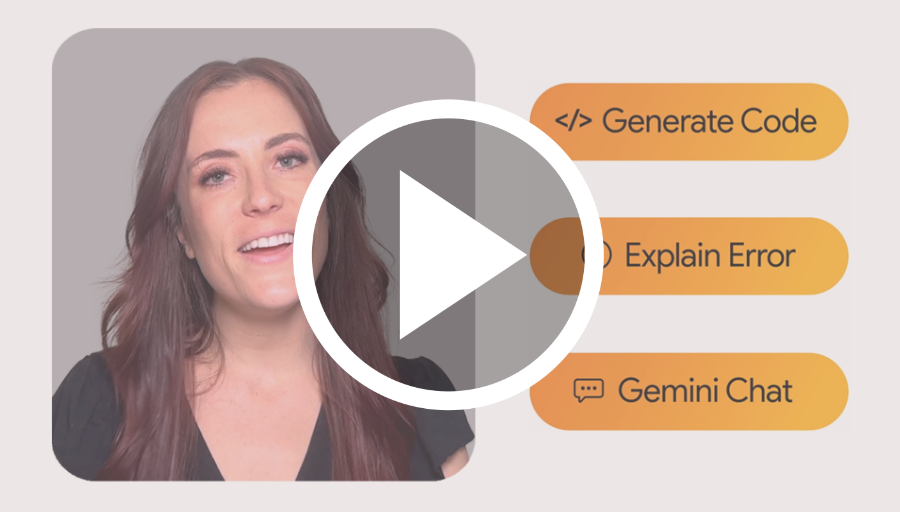
  </a>
</center>

<div class="markdown-google-sans">
  <h2>What is Colab?</h2>
</div>

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) or [Colab Features You May Have Missed](https://www.youtube.com/watch?v=rNgswRZ2C1Y) to learn more, or just get started below!

<div class="markdown-google-sans">

## **Getting started**
</div>

The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code.

For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

<div class="markdown-google-sans">

## Data science
</div>

With Colab you can harness the full power of popular Python libraries to analyze and visualize data. The code cell below uses **numpy** to generate some random data, and uses **matplotlib** to visualize it. To edit the code, just click the cell and start editing.

You can import your own data into Colab notebooks from your Google Drive account, including from spreadsheets, as well as from Github and many other sources. To learn more about importing data, and how Colab can be used for data science, see the links below under [Working with Data](#working-with-data).

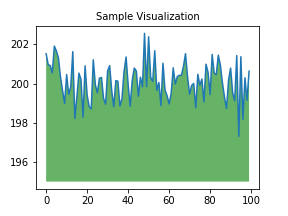

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Colab notebooks execute code on Google's cloud servers, meaning you can leverage the power of Google hardware, including [GPUs and TPUs](#using-accelerated-hardware), regardless of the power of your machine. All you need is a browser.

For example, if you find yourself waiting for **pandas** code to finish running and want to go faster, you can switch to a GPU Runtime and use libraries like [RAPIDS cuDF](https://rapids.ai/cudf-pandas) that provide zero-code-change acceleration.

To learn more about accelerating pandas on Colab, see the [10 minute guide](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb) or
 [US stock market data analysis demo](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb).

<div class="markdown-google-sans">

## Machine learning
</div>

With Colab you can import an image dataset, train an image classifier on it, and evaluate the model, all in just [a few lines of code](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb).

Colab is used extensively in the machine learning community with applications including:
- Getting started with TensorFlow
- Developing and training neural networks
- Experimenting with TPUs
- Disseminating AI research
- Creating tutorials

To see sample Colab notebooks that demonstrate machine learning applications, see the [machine learning examples](#machine-learning-examples) below.

<div class="markdown-google-sans">

## More Resources

### Working with Notebooks in Colab

</div>

- [Overview of Colab](/notebooks/basic_features_overview.ipynb)
- [Guide to Markdown](/notebooks/markdown_guide.ipynb)
- [Importing libraries and installing dependencies](/notebooks/snippets/importing_libraries.ipynb)
- [Saving and loading notebooks in GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Interactive forms](/notebooks/forms.ipynb)
- [Interactive widgets](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Working with Data
</div>

- [Loading data: Drive, Sheets, and Google Cloud Storage](/notebooks/io.ipynb)
- [Charts: visualizing data](/notebooks/charts.ipynb)
- [Getting started with BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Machine Learning

<div>

These are a few of the notebooks related to Machine Learning, including Google's online Machine Learning course. See the [full course website](https://developers.google.com/machine-learning/crash-course/) for more.
- [Intro to Pandas DataFrame](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Intro to RAPIDS cuDF to accelerate pandas](https://nvda.ws/rapids-cudf)
- [Getting Started with cuML's accelerator mode](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Using Accelerated Hardware
</div>

- [Train a CNN to classify handwritten digits on the MNIST dataset using Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Train a Vision Transformer (ViT) for image classification with JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Text classification with a transformer language model using JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Featured examples

</div>

- [Train a miniGPT language model with JAX AI Stack](https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html)
- [LoRA/QLoRA finetuning for LLM using Tunix](https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb)
- [Parameter-efficient fine-tuning of Gemma with LoRA and QLoRA](https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/)
- [Loading Hugging Face Transformers Checkpoints](https://keras.io/keras_hub/guides/hugging_face_keras_integration/)
- [8-bit Integer Quantization in Keras](https://keras.io/guides/int8_quantization_in_keras/)
- [Float8 training and inference with a simple Transformer model](https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/)
- [Pretraining a Transformer from scratch with KerasHub](https://keras.io/keras_hub/guides/transformer_pretraining/)
- [Simple MNIST convnet](https://keras.io/examples/vision/mnist_convnet/)
- [Image classification from scratch using Keras 3](https://keras.io/examples/vision/image_classification_from_scratch/)
- [Image Classification with KerasHub](https://keras.io/keras_hub/guides/classification_with_keras_hub/)
